# Projeto de Reconhecimento de Padrões
## Avaliação comparativa de 5 modelos de *Machine Learning* (sendo 1 híbrido) em 10 bases de dados públicas

**Disciplina:** Reconhecimento de Padrões (Pós-Graduação em Engenharia da Computação)

### Objetivo
Comparar, sob um mesmo protocolo experimental, cinco classificadores amplamente
utilizados em reconhecimento de padrões, avaliando-os em dez bases de dados
públicas e distintas. Ao final, o notebook gera automaticamente um **relatório em PDF**
com os resultados, a explicação de cada métrica de validação e a análise estatística
da comparação.

### Modelos avaliados
| # | Modelo | Família | Papel no estudo |
|---|--------|---------|-----------------|
| 1 | k-Vizinhos Mais Próximos (KNN) | Baseado em instâncias / distância | Referência não paramétrica |
| 2 | Máquina de Vetores de Suporte (SVM, kernel RBF) | Margem máxima / kernel | Classificador de fronteira não linear |
| 3 | Floresta Aleatória (Random Forest) | Comitê homogêneo de árvores (*bagging*) | Comitê robusto, pouco sensível à escala |
| 4 | Perceptron Multicamadas (MLP) | Rede neural *feed-forward* | Modelo conexionista |
| 5 | **Híbrido – Stacking (KNN + SVM + RF → Regressão Logística)** | Comitê heterogêneo em dois níveis | **Modelo híbrido** |

### Organização do notebook
1. Configuração do ambiente (inclui o registro do hardware e do software)
2. Bases de dados (carregamento e caracterização)
3. Definição dos modelos
4. Métricas de validação
5. Protocolo experimental (validação cruzada estratificada)
6. Consolidação dos resultados
7. Testes de hipótese (Friedman-Nemenyi e ANOVA-Tukey)
8. Visualizações
9. Geração do relatório PDF (com o ambiente de execução no Apêndice B)

> **Reprodutibilidade:** todas as fontes de aleatoriedade usam a mesma semente
> (`SEMENTE`), e todos os modelos são avaliados exatamente nas mesmas partições.

## 1. Configuração do ambiente

A célula abaixo instala as dependências (necessário apenas na primeira execução;
no Google Colab quase todas já estão presentes, exceto `reportlab`). A biblioteca
`psutil` é opcional: sem ela, parte das informações de hardware é lida
diretamente do sistema operacional.

In [1]:
# Instalação das dependências. Comente esta linha se o ambiente já estiver preparado.
%pip install -q numpy pandas scipy scikit-learn matplotlib reportlab joblib psutil


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python3.10 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# ----------------------------------------------------------------------------
# Marco zero do tempo de execução: registrado antes de qualquer outra importação.
# ----------------------------------------------------------------------------
import time
from datetime import datetime

INICIO_NOTEBOOK = time.perf_counter()           # relógio de alta resolução
INICIO_DATA_HORA = datetime.now().astimezone()  # data e hora local, com fuso

# ----------------------------------------------------------------------------
# Importações
# ----------------------------------------------------------------------------
import io
import json
import os
import platform
import shutil
import subprocess
import sys
import urllib.request
import warnings
from importlib import metadata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter
import joblib
from joblib import Parallel, delayed, effective_n_jobs
from scipy import stats
from scipy.stats import studentized_range

import sklearn
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.datasets import load_breast_cancer, load_digits, load_wine
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             cohen_kappa_score, f1_score, log_loss,
                             matthews_corrcoef, precision_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC

# ----------------------------------------------------------------------------
# Parâmetros globais do experimento
# ----------------------------------------------------------------------------
SEMENTE = 42          # semente única para todas as fontes de aleatoriedade
N_FOLDS = 10          # número de partições da validação cruzada externa
N_FOLDS_INTERNOS = 5  # partições internas usadas pelo Stacking (meta-atributos)
ALFA = 0.05           # nível de significância dos testes estatísticos
N_JOBS = -1           # núcleos usados em paralelo (-1 = todos)

DIR_DADOS = Path("dados")   # cache local das bases baixadas
DIR_SAIDA = Path("saida")   # figuras, tabelas (CSV) e relatório PDF
DIR_DADOS.mkdir(exist_ok=True)
DIR_SAIDA.mkdir(exist_ok=True)
ARQUIVO_PDF = DIR_SAIDA / "relatorio_comparacao_modelos.pdf"

np.random.seed(SEMENTE)

### 1.1 Ambiente de execução e tempos

Para que o experimento possa ser reproduzido e os tempos interpretados, o
notebook registra automaticamente **onde** foi executado:

* **hardware:** processador, núcleos, memória RAM e GPU;
* **software:** sistema operacional, versão do Python, interface (Jupyter,
  Colab), versões das bibliotecas e biblioteca de álgebra linear (BLAS);
* **tempos:** início e fim da execução, duração de cada etapa do notebook e
  tempo de parede da validação cruzada de cada modelo em cada base.

A coleta funciona em Linux, Windows e macOS; quando uma informação não está
disponível no sistema, o campo é marcado como "não informado". Tudo é
reproduzido no **Apêndice B do PDF** e salvo em `saida/ambiente_execucao.json`.

> **Medição dos tempos:** cada etapa é medida do fim da etapa anterior até o seu
> próprio fim. Os valores só são representativos quando o notebook é executado
> de forma contínua (*Executar tudo*); pausas entre células entram na contagem.

In [3]:
try:
    import psutil  # opcional: informações de hardware mais completas e portáveis
except ImportError:
    psutil = None

NAO_INFORMADO = "não informado"


def _ler_texto(caminho: str) -> str:
    """Lê um arquivo de texto do sistema (ex.: /proc/cpuinfo); '' se não existir."""
    try:
        return Path(caminho).read_text(errors="ignore")
    except OSError:
        return ""


def _comando(*args) -> str:
    """Executa um comando do sistema e devolve sua saída; '' se não existir ou falhar."""
    if shutil.which(args[0]) is None:
        return ""
    try:
        return subprocess.run(args, capture_output=True, text=True, timeout=10).stdout.strip()
    except (OSError, subprocess.SubprocessError):
        return ""


def _processador() -> str:
    """Modelo comercial do processador, lido da fonte própria de cada sistema."""
    sistema = platform.system()
    if sistema == "Linux":
        for linha in _ler_texto("/proc/cpuinfo").splitlines():
            if linha.lower().startswith("model name"):
                return linha.split(":", 1)[1].strip()
    elif sistema == "Darwin":
        nome = _comando("sysctl", "-n", "machdep.cpu.brand_string")
        if nome:
            return nome
    elif sistema == "Windows":
        try:
            import winreg
            chave = winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE,
                                   r"HARDWARE\DESCRIPTION\System\CentralProcessor\0")
            return winreg.QueryValueEx(chave, "ProcessorNameString")[0].strip()
        except OSError:
            pass
    return platform.processor() or NAO_INFORMADO


def _nucleos_fisicos():
    """Número de núcleos físicos (sem contar hyper-threading)."""
    if psutil is not None:
        return psutil.cpu_count(logical=False)
    if platform.system() == "Linux":  # pares únicos (soquete, núcleo) em /proc/cpuinfo
        pares, soquete = set(), None
        for linha in _ler_texto("/proc/cpuinfo").splitlines():
            if linha.startswith("physical id"):
                soquete = linha.split(":", 1)[1].strip()
            elif linha.startswith("core id"):
                pares.add((soquete, linha.split(":", 1)[1].strip()))
        return len(pares) or None
    return None


def _frequencia() -> str:
    """Frequência do processador informada pelo sistema (nem sempre disponível)."""
    try:
        freq = psutil.cpu_freq() if psutil is not None else None
    except (AttributeError, NotImplementedError, OSError, RuntimeError):
        freq = None
    if freq and freq.max:
        return f"{freq.max / 1000:.2f} GHz (máxima)".replace(".", ",")
    if freq and freq.current:
        return f"{freq.current / 1000:.2f} GHz (atual)".replace(".", ",")
    return NAO_INFORMADO


def _memoria_gib() -> tuple:
    """Memória RAM (total, disponível) em GiB."""
    if psutil is not None:
        memoria = psutil.virtual_memory()
        return memoria.total / 2**30, memoria.available / 2**30
    if platform.system() == "Linux":
        info = {}
        for linha in _ler_texto("/proc/meminfo").splitlines():
            partes = linha.split()
            if len(partes) >= 2 and partes[1].isdigit():
                info[partes[0].rstrip(":")] = int(partes[1]) / 2**20  # kB -> GiB
        return info.get("MemTotal", np.nan), info.get("MemAvailable", np.nan)
    if platform.system() == "Darwin":
        total = _comando("sysctl", "-n", "hw.memsize")
        return (int(total) / 2**30 if total.isdigit() else np.nan), np.nan
    return np.nan, np.nan


def _gpu() -> str:
    """GPUs NVIDIA detectadas (o scikit-learn não as utiliza: tudo roda em CPU)."""
    saida = _comando("nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader")
    deteccao = saida.replace("\n", "; ") if saida else "nenhuma GPU NVIDIA detectada"
    return f"{deteccao} (não utilizada: os modelos do scikit-learn executam em CPU)"


def _sistema_operacional() -> str:
    sistema = platform.system()
    if sistema == "Linux":
        try:
            nome = platform.freedesktop_os_release().get("PRETTY_NAME", "Linux")
        except (OSError, AttributeError):
            nome = "Linux"
        return f"{nome} (kernel {platform.release()})"
    if sistema == "Darwin":
        return f"macOS {platform.mac_ver()[0]}"
    if sistema == "Windows":
        return f"Windows {platform.release()} (build {platform.version()})"
    return platform.platform()


def _interface() -> str:
    """Onde o código está rodando: Colab, Kaggle, Jupyter ou script."""
    if "google.colab" in sys.modules:
        return "Google Colab"
    if os.environ.get("KAGGLE_KERNEL_RUN_TYPE"):
        return "Kaggle Notebooks"
    if "ipykernel" in sys.modules:
        return "Jupyter (VS Code)" if os.environ.get("VSCODE_PID") else "Jupyter (ipykernel)"
    return "script Python"


def _ambiente_python() -> str:
    if os.environ.get("CONDA_DEFAULT_ENV"):
        return f"conda (ambiente '{os.environ['CONDA_DEFAULT_ENV']}')"
    if sys.prefix != sys.base_prefix:
        return "ambiente virtual (venv)"
    return "instalação do sistema"


def _algebra_linear() -> str:
    """Bibliotecas de álgebra linear/paralelismo carregadas (BLAS, OpenMP) e nº de threads."""
    try:
        from threadpoolctl import threadpool_info
        itens = threadpool_info()
    except Exception:  # threadpoolctl ausente ou sem permissão para inspecionar
        return NAO_INFORMADO
    # Pacote que carregou cada biblioteca, deduzido do caminho do arquivo (o NumPy é
    # verificado antes do SciPy porque sua cópia do OpenBLAS se chama "scipy_openblas").
    donos = (("numpy", "NumPy"), ("scikit_learn", "scikit-learn"), ("sklearn", "scikit-learn"), ("scipy", "SciPy"))
    descricoes = []
    for info in itens:
        caminho = (info.get("filepath") or "").lower()
        dono = next((nome for chave, nome in donos if chave in caminho), None)
        threads = info.get("num_threads")
        texto = f"{info.get('internal_api')} {info.get('version') or ''}".strip()
        texto += f", via {dono}" if dono else ""
        descricoes.append(f"{texto} ({threads} thread{'' if threads == 1 else 's'})")
    return "; ".join(dict.fromkeys(descricoes)) or NAO_INFORMADO  # remove repetições, mantém a ordem


def _variaveis_threads() -> str:
    """Variáveis de ambiente que limitam threads das bibliotecas numéricas."""
    nomes = ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS",
             "NUMEXPR_NUM_THREADS"]
    definidas = [f"{nome}={os.environ[nome]}" for nome in nomes if nome in os.environ]
    return ", ".join(definidas) or "nenhuma definida"


def _versao(pacote: str) -> str:
    try:
        return metadata.version(pacote)
    except metadata.PackageNotFoundError:
        return "não instalado"


def _gib(valor) -> str:
    return NAO_INFORMADO if np.isnan(valor) else f"{valor:.1f} GiB".replace(".", ",")


PACOTES_REGISTRADOS = ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "joblib",
                       "threadpoolctl", "reportlab", "psutil", "ipykernel"]


def coletar_ambiente() -> dict:
    """Coleta hardware, software e versões das bibliotecas da máquina atual."""
    ram_total, ram_livre = _memoria_gib()
    fisicos = _nucleos_fisicos()
    return {
        "Hardware": {
            "Processador": _processador(),
            "Arquitetura": platform.machine() or NAO_INFORMADO,
            "Núcleos físicos": str(fisicos) if fisicos else NAO_INFORMADO,
            "Núcleos lógicos (threads)": str(os.cpu_count()),
            "Núcleos disponíveis ao processo": str(joblib.cpu_count()),
            "Frequência do processador": _frequencia(),
            "Memória RAM total": _gib(ram_total),
            "Memória RAM disponível no início": _gib(ram_livre),
            "GPU": _gpu(),
        },
        "Software": {
            "Sistema operacional": _sistema_operacional(),
            "Python": f"{platform.python_version()} ({platform.python_implementation()}; "
                      f"compilado com {platform.python_compiler().strip()})",
            "Interface de execução": _interface(),
            "Ambiente Python": _ambiente_python(),
            "Álgebra linear e paralelismo": _algebra_linear(),
            "Variáveis de limite de threads": _variaveis_threads(),
        },
        "Bibliotecas": {pacote: _versao(pacote) for pacote in PACOTES_REGISTRADOS},
    }


def formatar_duracao(segundos: float) -> str:
    """Formata uma duração em segundos como '2,3 s', '4 min 05 s' ou '1 h 02 min'."""
    if segundos < 60:
        return f"{segundos:.1f} s".replace(".", ",")
    minutos, seg = divmod(int(round(segundos)), 60)
    if minutos < 60:
        return f"{minutos} min {seg:02d} s"
    horas, minutos = divmod(minutos, 60)
    return f"{horas} h {minutos:02d} min"


# Registro das etapas: cada chamada mede o tempo desde a etapa anterior.
ETAPAS = {}                          # {nome da etapa: duração em segundos}
_MARCO = {"anterior": INICIO_NOTEBOOK}


def registrar_etapa(nome: str):
    """Registra a duração da etapa que termina agora (desde o marco anterior)."""
    agora = time.perf_counter()
    ETAPAS[nome] = agora - _MARCO["anterior"]
    _MARCO["anterior"] = agora


AMBIENTE = coletar_ambiente()
print(f"Execução iniciada em {INICIO_DATA_HORA:%d/%m/%Y %H:%M:%S} (UTC{INICIO_DATA_HORA:%z})\n")
for grupo, itens in AMBIENTE.items():
    print(grupo.upper())
    for chave, valor in itens.items():
        print(f"  {chave:<34} {valor}")
    print()
registrar_etapa("Configuração e registro do ambiente")

Execução iniciada em 17/11/2026 21:51:51 (UTC-0300)

HARDWARE
  Processador                        Intel(R) Core(TM) 7 150U
  Arquitetura                        x86_64
  Núcleos físicos                    10
  Núcleos lógicos (threads)          12
  Núcleos disponíveis ao processo    12
  Frequência do processador          4,47 GHz (máxima)
  Memória RAM total                  31,0 GiB
  Memória RAM disponível no início   20,3 GiB
  GPU                                NVIDIA-SMI has failed because it couldn't communicate with the NVIDIA driver. Make sure that the latest NVIDIA driver is installed and running. (não utilizada: os modelos do scikit-learn executam em CPU)

SOFTWARE
  Sistema operacional                Ubuntu 22.04.5 LTS (kernel 6.8.0-138-generic)
  Python                             3.10.12 (CPython; compilado com GCC 11.4.0)
  Interface de execução              Jupyter (ipykernel)
  Ambiente Python                    instalação do sistema
  Álgebra linear e paralelismo    

## 2. Bases de dados

Foram selecionadas **10 bases públicas de classificação**, todas clássicas na
literatura de reconhecimento de padrões e escolhidas para variar em:

* **domínio** (medicina, química, imagens, radar/sonar, fala, finanças, agricultura);
* **número de instâncias** (de 178 a ~5.400);
* **dimensionalidade** (de 4 a 64 atributos);
* **número de classes** (binárias e multiclasse, de 2 a 10);
* **balanceamento** entre classes (de balanceadas a 5:1).

**Forma de acesso.** Três bases são distribuídas com o próprio scikit-learn
(cópias das versões do *UCI Machine Learning Repository*). As outras sete são
baixadas em CSV de um repositório público no GitHub que espelha os arquivos
originais do UCI/OpenML, e ficam guardadas em `dados/` (as execuções seguintes
funcionam sem internet).

Todas possuem apenas atributos numéricos e não possuem valores ausentes
codificados, de modo que o único pré-processamento necessário é a padronização
(feita *dentro* de cada partição — ver Seção 3).

In [4]:
# Endereço-base do espelho público (GitHub) com os arquivos CSV originais.
URL_ESPELHO = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/"


def _carregar_csv(arquivo: str):
    """Baixa (uma única vez) um CSV sem cabeçalho cujo ÚLTIMO campo é a classe.

    O arquivo é guardado em ``DIR_DADOS`` para que as próximas execuções não
    dependam de conexão com a internet.
    """
    destino = DIR_DADOS / arquivo
    if not destino.exists():
        urllib.request.urlretrieve(URL_ESPELHO + arquivo, destino)
    df = pd.read_csv(destino, header=None)
    X = df.iloc[:, :-1].to_numpy(dtype=float)
    y = df.iloc[:, -1].to_numpy()
    return X, y


def _carregar_sklearn(funcao):
    """Carrega uma base embutida no scikit-learn."""
    dados = funcao()
    return dados.data.astype(float), dados.target


# Catálogo das bases: nome, domínio, repositório de origem e função de carga.
CATALOGO_BASES = [
    dict(nome="New Thyroid", dominio="Medicina (função da tireoide)",
         origem="UCI ML Repository (Thyroid Disease - new-thyroid)", acesso="espelho GitHub",
         carregar=lambda: _carregar_csv("new-thyroid.csv")),
    dict(nome="Wine", dominio="Química (cultivares de vinho)",
         origem="UCI ML Repository (Wine)", acesso="scikit-learn",
         carregar=lambda: _carregar_sklearn(load_wine)),
    dict(nome="Breast Cancer", dominio="Medicina (diagnóstico de tumores)",
         origem="UCI ML Repository (Breast Cancer Wisconsin Diagnostic)", acesso="scikit-learn",
         carregar=lambda: _carregar_sklearn(load_breast_cancer)),
    dict(nome="Digits", dominio="Imagens (dígitos manuscritos 8x8)",
         origem="UCI ML Repository (Optical Recognition of Handwritten Digits)", acesso="scikit-learn",
         carregar=lambda: _carregar_sklearn(load_digits)),
    dict(nome="Pima Diabetes", dominio="Medicina (diagnóstico de diabetes)",
         origem="NIDDK / UCI; disponível no OpenML (diabetes)", acesso="espelho GitHub",
         carregar=lambda: _carregar_csv("pima-indians-diabetes.csv")),
    dict(nome="Sonar", dominio="Sinais de sonar (minas x rochas)",
         origem="UCI ML Repository (Connectionist Bench - Sonar)", acesso="espelho GitHub",
         carregar=lambda: _carregar_csv("sonar.csv")),
    dict(nome="Ionosphere", dominio="Sinais de radar (ionosfera)",
         origem="UCI ML Repository (Ionosphere)", acesso="espelho GitHub",
         carregar=lambda: _carregar_csv("ionosphere.csv")),
    dict(nome="Banknote", dominio="Finanças (autenticação de cédulas)",
         origem="UCI ML Repository (Banknote Authentication)", acesso="espelho GitHub",
         carregar=lambda: _carregar_csv("banknote_authentication.csv")),
    dict(nome="Seeds", dominio="Agricultura (variedades de trigo)",
         origem="UCI ML Repository (Seeds)", acesso="espelho GitHub",
         carregar=lambda: _carregar_csv("wheat-seeds.csv")),
    dict(nome="Phoneme", dominio="Fala (fonemas nasais x orais)",
         origem="Projeto ELENA; disponível no OpenML/KEEL (phoneme)", acesso="espelho GitHub",
         carregar=lambda: _carregar_csv("phoneme.csv")),
]

# Carregamento efetivo. Os rótulos são convertidos para inteiros 0..K-1
# (LabelEncoder), o que uniformiza o tratamento de classes textuais e numéricas.
BASES = {}
linhas_resumo = []
for item in CATALOGO_BASES:
    X, y_bruto = item["carregar"]()
    y = LabelEncoder().fit_transform(y_bruto)
    assert not np.isnan(X).any(), f"Valores ausentes em {item['nome']}"
    BASES[item["nome"]] = (X, y)
    contagem = np.bincount(y)
    linhas_resumo.append({
        "Base": item["nome"],
        "Domínio": item["dominio"],
        "Instâncias": X.shape[0],
        "Atributos": X.shape[1],
        "Classes": len(contagem),
        # Razão de desbalanceamento: classe majoritária / classe minoritária
        "Desbalanceamento": round(contagem.max() / contagem.min(), 2),
        "Origem": item["origem"],
        "Acesso": item["acesso"],
    })

RESUMO_BASES = pd.DataFrame(linhas_resumo)
NOMES_BASES = list(BASES)
registrar_etapa("Carga das bases de dados")
RESUMO_BASES.drop(columns=["Origem"])

,Base,Domínio,Instâncias,Atributos,Classes,Desbalanceamento,Acesso
0,New Thyroid,Medicina (função da tireoide),215,5,3,5.00,espelho GitHub
1,Wine,Química (cultivares de vinho),178,13,3,1.48,scikit-learn
2,Breast Cancer,Medicina (diagnóstico de tumores),569,30,2,1.68,scikit-learn
3,Digits,Imagens (dígitos manuscritos 8x8),1797,64,10,1.05,scikit-learn
4,Pima Diabetes,Medicina (diagnóstico de diabetes),768,8,2,1.87,espelho GitHub
5,Sonar,Sinais de sonar (minas x rochas),208,60,2,1.14,espelho GitHub
6,Ionosphere,Sinais de radar (ionosfera),351,34,2,1.79,espelho GitHub
7,Banknote,Finanças (autenticação de cédulas),1372,4,2,1.25,espelho GitHub
8,Seeds,Agricultura (variedades de trigo),210,7,3,1.00,espelho GitHub
9,Phoneme,Fala (fonemas nasais x orais),5404,5,2,2.41,espelho GitHub


## 3. Definição dos modelos

Cada modelo é encapsulado em um `Pipeline` contendo a **padronização**
(`StandardScaler`: média 0 e desvio-padrão 1) seguida do classificador.
Isso garante que as estatísticas de padronização sejam estimadas **somente com
os dados de treino de cada partição**, evitando vazamento de informação
(*data leakage*) do conjunto de teste.

### Por que estes cinco modelos?
O critério geral foi cobrir **paradigmas de aprendizado diferentes**, de modo
que a comparação contraste *formas distintas de reconhecer padrões*, e não
variações de uma mesma ideia. Cada modelo tem ainda um motivo específico:

| Modelo | Motivo da seleção |
|--------|-------------------|
| **KNN** | Representa o paradigma de **similaridade/distância** e é a referência clássica da área (Cover e Hart, 1967): não faz suposição sobre a distribuição dos dados e praticamente não tem treino. Funciona como *linha de base*: um modelo mais complexo só se justifica se superá-lo. |
| **SVM-RBF** | Representa o paradigma de **margem máxima**. Tem forte fundamentação teórica (minimização do risco estrutural), gera fronteiras não lineares pelo kernel e costuma ir bem com poucas amostras e muitos atributos, situação de bases como Sonar e Ionosphere. |
| **Random Forest** | Representa os **comitês homogêneos de árvores** (*bagging*). É robusto a ruído e à escala dos atributos, pouco sensível a hiperparâmetros e figura entre os melhores classificadores em estudos comparativos amplos com bases tabulares (Fernández-Delgado et al., 2014). |
| **MLP** | Representa o paradigma **conexionista** (redes neurais). É um aproximador universal de funções e a base das redes profundas; sua inclusão permite verificar como uma rede neural se comporta em bases tabulares pequenas e médias. |
| **Híbrido (Stacking)** | Atende ao requisito de um modelo híbrido e testa a hipótese central dos sistemas de múltiplos classificadores: **combinar modelos com vieses indutivos diferentes** (distância, margem e árvores) pode superar cada um isoladamente, pois eles tendem a errar em exemplos diferentes. O meta-classificador *aprende* como ponderar os modelos-base, em vez de usar um voto fixo. O MLP ficou fora do nível 0 para conter o custo computacional e permanecer como comparador independente. |

### Modelo híbrido: *Stacking*
O modelo híbrido combina três classificadores de naturezas distintas
(distância, margem e árvores) em uma arquitetura de dois níveis
(*stacked generalization*, Wolpert, 1992):

* **Nível 0:** KNN, SVM-RBF e Random Forest produzem probabilidades por classe;
* **Nível 1:** uma Regressão Logística (meta-classificador) aprende a combinar
  essas probabilidades.

As probabilidades do nível 0 usadas para treinar o meta-classificador são
obtidas por validação cruzada interna (`cv=5`), para que ele não seja treinado
com predições feitas sobre exemplos que os modelos-base já viram.

**Hiperparâmetros.** Foram adotadas configurações fixas e usuais na literatura
(em geral os padrões do scikit-learn), idênticas para todas as bases. Assim a
comparação mede o desempenho "de fábrica" de cada algoritmo; a busca de
hiperparâmetros por validação cruzada aninhada é uma extensão natural do trabalho.

In [5]:
def _com_padronizacao(classificador):
    """Devolve um Pipeline: padronização z-score + classificador."""
    return Pipeline([("padronizacao", StandardScaler()), ("clf", classificador)])


def criar_modelos(semente: int = SEMENTE) -> dict:
    """Cria o dicionário {nome: estimador} com os 5 modelos do estudo."""
    knn = _com_padronizacao(KNeighborsClassifier(n_neighbors=5))
    # A SVM não produz probabilidades nativamente. Elas são obtidas por calibração
    # de Platt (regressão sigmoide sobre a função de decisão, ajustada com
    # validação cruzada interna de 5 partições), necessárias para a AUC-ROC, a
    # perda logarítmica e o Stacking. É o mesmo procedimento de SVC(probability=True),
    # escrito de forma explícita por ser a forma recomendada nas versões recentes
    # do scikit-learn.
    svm = _com_padronizacao(CalibratedClassifierCV(
        SVC(kernel="rbf", C=1.0, gamma="scale"), method="sigmoid", cv=5, ensemble=False))
    rf = RandomForestClassifier(n_estimators=200, random_state=semente, n_jobs=1)
    mlp = _com_padronizacao(MLPClassifier(hidden_layer_sizes=(100,), activation="relu",
                                          solver="adam", max_iter=1000,
                                          random_state=semente))
    # Modelo híbrido: comitê heterogêneo em dois níveis.
    hibrido = StackingClassifier(
        estimators=[("knn", clone(knn)), ("svm", clone(svm)), ("rf", clone(rf))],
        final_estimator=LogisticRegression(max_iter=1000),
        stack_method="predict_proba",
        cv=StratifiedKFold(n_splits=N_FOLDS_INTERNOS, shuffle=True, random_state=semente),
        n_jobs=1,
    )
    return {"KNN": knn, "SVM-RBF": svm, "Random Forest": rf, "MLP": mlp,
            "Híbrido (Stacking)": hibrido}


MODELOS = criar_modelos()
NOMES_MODELOS = list(MODELOS)

# Descrição textual dos modelos (usada no relatório PDF).
DESCRICAO_MODELOS = {
    "KNN": ("Classifica cada exemplo pela classe majoritária entre os k exemplos de treino "
            "mais próximos (distância euclidiana). Não paramétrico e sem fase de treino explícita.",
            "k = 5; pesos uniformes; atributos padronizados"),
    "SVM-RBF": ("Busca o hiperplano de margem máxima em um espaço de características induzido "
                "pelo kernel gaussiano (RBF), produzindo fronteiras de decisão não lineares.",
                "C = 1; gamma = 'scale'; probabilidades por calibração de Platt; atributos padronizados"),
    "Random Forest": ("Comitê homogêneo de árvores de decisão treinadas em amostras bootstrap, "
                      "com sorteio de atributos em cada nó; a predição é a média das árvores.",
                      "200 árvores; raiz quadrada do nº de atributos por divisão"),
    "MLP": ("Rede neural feed-forward com uma camada oculta, treinada por retropropagação "
            "do gradiente; aproxima funções de decisão não lineares.",
            "1 camada oculta com 100 neurônios ReLU; otimizador Adam; até 1000 épocas; atributos padronizados"),
    "Híbrido (Stacking)": ("Modelo híbrido em dois níveis: KNN, SVM-RBF e Random Forest geram "
                           "probabilidades por classe, que são combinadas por uma Regressão Logística "
                           "(meta-classificador) treinada com predições de validação cruzada interna.",
                           f"Bases: os três modelos acima; meta: Regressão Logística; cv interna = {N_FOLDS_INTERNOS}"),
}

# Motivo da seleção de cada modelo (usado no relatório PDF).
MOTIVO_MODELOS = {
    "KNN": ("Representa o paradigma de similaridade (distância) e é a referência clássica da área "
            "(Cover e Hart, 1967): não faz suposição sobre a distribuição dos dados e praticamente não tem fase "
            "de treino. Foi incluído como linha de base: um modelo mais complexo só se justifica se superá-lo."),
    "SVM-RBF": ("Representa o paradigma de margem máxima. Tem forte fundamentação teórica (minimização do risco "
                "estrutural), produz fronteiras não lineares por meio do kernel e costuma apresentar bom "
                "desempenho com poucas amostras e muitos atributos, situação de bases como Sonar e Ionosphere."),
    "Random Forest": ("Representa os comitês homogêneos de árvores (bagging). É robusto a ruído e à escala dos "
                      "atributos, pouco sensível a hiperparâmetros e figura entre os melhores classificadores em "
                      "estudos comparativos amplos com bases tabulares (Fernández-Delgado et al., 2014)."),
    "MLP": ("Representa o paradigma conexionista (redes neurais). É um aproximador universal de funções e a base "
            "das redes profundas; sua inclusão permite verificar como uma rede neural se comporta em bases "
            "tabulares de pequeno e médio porte."),
    "Híbrido (Stacking)": ("Atende ao requisito de um modelo híbrido e testa a hipótese central dos sistemas de "
                           "múltiplos classificadores: combinar modelos com vieses indutivos diferentes (distância, "
                           "margem e árvores) pode superar cada um isoladamente, pois eles tendem a errar em "
                           "exemplos diferentes. O meta-classificador aprende como ponderar os modelos-base, em vez "
                           "de aplicar um voto fixo. O MLP ficou fora do nível 0 para conter o custo computacional "
                           "e permanecer como comparador independente."),
}

# Cor fixa por modelo (a cor acompanha o modelo em TODAS as figuras).
CORES_MODELOS = dict(zip(NOMES_MODELOS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))

## 4. Métricas de validação

São calculadas **nove métricas de qualidade** mais o **tempo de treinamento**.
Nenhuma métrica isolada descreve completamente um classificador; por isso
combinam-se métricas de:

* **acerto global** (acurácia, acurácia balanceada);
* **acerto por classe** (precisão, revocação e F1 em média *macro*);
* **concordância corrigida pelo acaso** (MCC e Kappa de Cohen);
* **qualidade das probabilidades** (AUC-ROC e perda logarítmica).

Em problemas multiclasse, precisão, revocação e F1 usam a média **macro**
(média simples entre as classes), que dá o mesmo peso a todas as classes,
independentemente do tamanho; a AUC usa a estratégia *um-contra-todos* (OvR)
com média macro.

O dicionário `METRICAS` centraliza, para cada métrica: nome, fórmula, intervalo,
valor ideal e os textos explicativos que serão impressos no relatório.

In [6]:
METRICAS = {
    "acuracia": dict(
        nome="Acurácia", sigla="ACC", maior_melhor=True, intervalo="[0, 1]", ideal="1",
        formula=r"$\mathrm{ACC}=\frac{VP+VN}{VP+VN+FP+FN}$",
        significado=("Proporção de exemplos classificados corretamente, considerando todas as classes. "
                     "É a probabilidade empírica de o classificador acertar um exemplo novo."),
        importancia=("É a medida mais direta e intuitiva de desempenho e a mais usada na literatura, o que "
                     "facilita a comparação com outros trabalhos. Sua limitação é ser dominada pela classe "
                     "majoritária: em bases desbalanceadas, um modelo que sempre prediz a classe mais "
                     "frequente obtém acurácia alta sem ter aprendido nada."),
        porque=("O ideal é 1 (100%), que significa que nenhum exemplo foi classificado incorretamente "
                "(FP = FN = 0). Como referência inferior usa-se a frequência da classe majoritária, e não zero."),
    ),
    "acuracia_balanceada": dict(
        nome="Acurácia balanceada", sigla="BAC", maior_melhor=True, intervalo="[0, 1]", ideal="1",
        formula=r"$\mathrm{BAC}=\frac{1}{K}\sum_{k=1}^{K}\frac{VP_k}{VP_k+FN_k}$",
        significado=("Média das taxas de acerto de cada classe (revocação por classe). Cada classe "
                     "contribui igualmente, qualquer que seja o seu número de exemplos."),
        importancia=("Corrige a principal deficiência da acurácia em bases desbalanceadas: um classificador "
                     "que ignora a classe minoritária é penalizado. Um classificador aleatório ou constante "
                     "obtém 1/K (0,5 no caso binário), o que fornece um piso de referência claro."),
        porque=("O ideal é 1, alcançado apenas quando todas as classes são integralmente reconhecidas. "
                "Valores próximos de 1/K indicam desempenho equivalente ao acaso."),
    ),
    "precisao_macro": dict(
        nome="Precisão (macro)", sigla="PREC", maior_melhor=True, intervalo="[0, 1]", ideal="1",
        formula=r"$\mathrm{PREC}=\frac{1}{K}\sum_{k=1}^{K}\frac{VP_k}{VP_k+FP_k}$",
        significado=("Entre os exemplos que o modelo atribuiu a uma classe, a fração que realmente pertence "
                     "a ela, em média sobre as classes. Mede a confiabilidade das predições positivas."),
        importancia=("É a métrica relevante quando o custo de um falso positivo é alto, por exemplo "
                     "classificar como fraude uma transação legítima ou indicar um tratamento desnecessário."),
        porque=("O ideal é 1, que corresponde à ausência de falsos positivos (FP = 0) em todas as classes: "
                "toda vez que o modelo afirma uma classe, ele está certo."),
    ),
    "revocacao_macro": dict(
        nome="Revocação / Sensibilidade (macro)", sigla="REC", maior_melhor=True, intervalo="[0, 1]", ideal="1",
        formula=r"$\mathrm{REC}=\frac{1}{K}\sum_{k=1}^{K}\frac{VP_k}{VP_k+FN_k}$",
        significado=("Entre os exemplos que realmente pertencem a uma classe, a fração que o modelo conseguiu "
                     "identificar, em média sobre as classes. Mede a capacidade de detecção (cobertura)."),
        importancia=("É a métrica relevante quando o custo de um falso negativo é alto, por exemplo deixar de "
                     "detectar uma doença ou uma mina. Precisão e revocação são conflitantes: aumentar uma "
                     "tende a reduzir a outra, por isso devem ser analisadas em conjunto. Com média macro, "
                     "a revocação coincide numericamente com a acurácia balanceada."),
        porque=("O ideal é 1, que corresponde à ausência de falsos negativos (FN = 0): nenhum exemplo de "
                "nenhuma classe deixa de ser reconhecido."),
    ),
    "f1_macro": dict(
        nome="F1-score (macro)", sigla="F1", maior_melhor=True, intervalo="[0, 1]", ideal="1",
        formula=r"$F1=\frac{1}{K}\sum_{k=1}^{K}\frac{2\,\mathrm{PREC}_k\,\mathrm{REC}_k}{\mathrm{PREC}_k+\mathrm{REC}_k}$",
        significado=("Média harmônica entre precisão e revocação de cada classe, em média sobre as classes. "
                     "Resume em um único número o compromisso entre os dois tipos de erro."),
        importancia=("Por usar a média harmônica, o F1 só é alto quando precisão e revocação são altas "
                     "simultaneamente; um modelo muito bom em uma e ruim na outra é penalizado. A versão "
                     "macro é adequada a bases desbalanceadas e é adotada neste trabalho como métrica "
                     "principal de comparação."),
        porque=("O ideal é 1, atingido somente quando precisão e revocação valem 1 em todas as classes, "
                "isto é, quando não há falsos positivos nem falsos negativos."),
    ),
    "mcc": dict(
        nome="Coeficiente de Correlação de Matthews", sigla="MCC", maior_melhor=True,
        intervalo="[-1, 1]", ideal="1",
        formula=r"$\mathrm{MCC}=\frac{VP\cdot VN-FP\cdot FN}{\sqrt{(VP+FP)(VP+FN)(VN+FP)(VN+FN)}}$",
        significado=("Coeficiente de correlação entre as classes reais e as preditas. Usa as quatro células "
                     "da matriz de confusão (a fórmula mostrada é a do caso binário; para K classes usa-se "
                     "a generalização calculada sobre a matriz de confusão completa)."),
        importancia=("É considerada uma das medidas mais informativas para classificação, pois só atinge "
                     "valores altos quando o modelo vai bem em todas as classes, positivas e negativas, "
                     "proporcionalmente ao tamanho de cada uma. É, portanto, robusta ao desbalanceamento, "
                     "situação em que acurácia e F1 podem ser otimistas."),
        porque=("O ideal é +1 (predição perfeita). O valor 0 equivale a uma predição aleatória e -1 indica "
                "discordância total entre predição e realidade."),
    ),
    "kappa": dict(
        nome="Kappa de Cohen", sigla="Kappa", maior_melhor=True, intervalo="[-1, 1]", ideal="1",
        formula=r"$\kappa=\frac{p_o-p_e}{1-p_e}$",
        significado=("Grau de concordância entre as classes preditas e as reais, descontada a concordância "
                     "esperada por puro acaso. Na fórmula, p_o é a concordância observada (a acurácia) e "
                     "p_e é a concordância esperada ao acaso, dadas as frequências das classes."),
        importancia=("Indica quanto do acerto do modelo excede o que se obteria por sorte. Uma acurácia de "
                     "90% em uma base em que 90% dos exemplos são de uma classe resulta em Kappa próximo de "
                     "zero, revelando que o modelo não agregou informação."),
        porque=("O ideal é 1 (concordância perfeita). O valor 0 indica concordância igual à do acaso e "
                "valores negativos indicam concordância pior que a do acaso."),
    ),
    "auc_roc": dict(
        nome="Área sob a curva ROC (OvR, macro)", sigla="AUC", maior_melhor=True, intervalo="[0, 1]", ideal="1",
        formula=r"$\mathrm{AUC}=\int_{0}^{1}\mathrm{TVP}\;d(\mathrm{TFP})=P\,(s(x^{+})>s(x^{-}))$",
        significado=("Probabilidade de o modelo atribuir a um exemplo positivo, escolhido ao acaso, um escore "
                     "maior que o de um exemplo negativo escolhido ao acaso. Corresponde à área sob a curva "
                     "que relaciona a taxa de verdadeiros positivos (TVP) à de falsos positivos (TFP) para "
                     "todos os limiares de decisão."),
        importancia=("Avalia a capacidade de ordenação (separação) do modelo independentemente do limiar de "
                     "decisão escolhido, ao contrário das métricas anteriores, que dependem de um único "
                     "limiar. É útil quando o ponto de operação será definido depois, conforme os custos."),
        porque=("O ideal é 1: existe um limiar que separa perfeitamente as classes. O valor 0,5 corresponde "
                "a um ordenamento aleatório."),
    ),
    "log_loss": dict(
        nome="Perda logarítmica (entropia cruzada)", sigla="LogLoss", maior_melhor=False,
        intervalo="[0, +inf)", ideal="0",
        formula=r"$\mathrm{LogLoss}=-\frac{1}{N}\sum_{i=1}^{N}\sum_{k=1}^{K}y_{ik}\,\ln\,p_{ik}$",
        significado=("Média do logaritmo negativo da probabilidade que o modelo atribuiu à classe correta "
                     "de cada exemplo (y_ik vale 1 se o exemplo i pertence à classe k; p_ik é a "
                     "probabilidade predita)."),
        importancia=("Avalia a qualidade das probabilidades, e não apenas da decisão final: penaliza "
                     "fortemente predições erradas feitas com alta confiança. É importante quando a "
                     "probabilidade será usada na tomada de decisão (risco, triagem, custo esperado)."),
        porque=("O ideal é 0, que só ocorre quando o modelo atribui probabilidade 1 à classe correta de "
                "todos os exemplos. É a única métrica de qualidade deste estudo em que menor é melhor; "
                "um modelo que distribui probabilidade uniforme entre K classes obtém ln(K)."),
    ),
    "tempo_treino": dict(
        nome="Tempo de treinamento", sigla="Tempo (s)", maior_melhor=False,
        intervalo="[0, +inf)", ideal="o menor possível",
        formula=None,
        significado=("Tempo, em segundos, gasto para treinar o modelo em uma partição da validação cruzada."),
        importancia=("Não mede qualidade preditiva, e sim custo computacional. Permite avaliar se o ganho de "
                     "desempenho de um modelo mais complexo (como o híbrido) compensa o custo adicional."),
        porque=("Quanto menor, melhor, desde que o desempenho preditivo seja equivalente. Os valores "
                "dependem do hardware e servem apenas para comparação relativa entre os modelos."),
    ),
}

# Métricas de qualidade preditiva (todas, exceto o tempo) e métrica principal.
METRICAS_QUALIDADE = [m for m in METRICAS if m != "tempo_treino"]
METRICA_PRINCIPAL = "f1_macro"


def calcular_metricas(y_real, y_pred, y_proba, classes) -> dict:
    """Calcula as nove métricas de qualidade para uma partição de teste.

    Parâmetros
    ----------
    y_real, y_pred : rótulos reais e preditos.
    y_proba        : matriz (n_exemplos, n_classes) de probabilidades preditas.
    classes        : vetor com todos os rótulos possíveis (ordem das colunas de y_proba).
    """
    if len(classes) == 2:
        # Caso binário: usa-se a probabilidade da classe positiva (coluna 1).
        auc = roc_auc_score(y_real, y_proba[:, 1])
    else:
        # Caso multiclasse: um-contra-todos (OvR) com média macro.
        auc = roc_auc_score(y_real, y_proba, multi_class="ovr", average="macro", labels=classes)
    return {
        "acuracia": accuracy_score(y_real, y_pred),
        "acuracia_balanceada": balanced_accuracy_score(y_real, y_pred),
        "precisao_macro": precision_score(y_real, y_pred, average="macro", zero_division=0),
        "revocacao_macro": recall_score(y_real, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_real, y_pred, average="macro", zero_division=0),
        "mcc": matthews_corrcoef(y_real, y_pred),
        "kappa": cohen_kappa_score(y_real, y_pred),
        "auc_roc": auc,
        "log_loss": log_loss(y_real, y_proba, labels=classes),
    }

## 5. Protocolo experimental

* **Validação cruzada estratificada com 10 partições** (*stratified 10-fold*):
  cada base é dividida em 10 partes que preservam a proporção das classes; cada
  parte é usada uma vez como teste e as outras nove como treino.
* **Comparação pareada:** as partições são geradas uma única vez por base
  (semente fixa) e **reutilizadas por todos os modelos**, de modo que as
  diferenças observadas se devem aos modelos, e não a divisões diferentes.
* Em cada partição o modelo é clonado (sem estado anterior), treinado, e as
  métricas são calculadas sobre o conjunto de teste.
* As partições são processadas em paralelo; o tempo de treino é, portanto,
  uma medida relativa.

> A execução completa leva alguns minutos (o modelo híbrido treina 3 modelos-base
> 6 vezes por partição: 5 da validação interna + 1 ajuste final).

In [7]:
def avaliar_particao(modelo, X, y, idx_treino, idx_teste, classes) -> dict:
    """Treina um clone do modelo em uma partição e devolve as métricas no teste."""
    estimador = clone(modelo)  # garante que nenhum estado é reaproveitado entre partições
    with warnings.catch_warnings():
        # O MLP pode atingir o limite de épocas antes do critério de parada em
        # algumas partições; o aviso é silenciado para não poluir a saída.
        warnings.simplefilter("ignore", category=ConvergenceWarning)
        inicio = time.perf_counter()
        estimador.fit(X[idx_treino], y[idx_treino])
        tempo = time.perf_counter() - inicio
    y_pred = estimador.predict(X[idx_teste])
    y_proba = estimador.predict_proba(X[idx_teste])
    resultado = calcular_metricas(y[idx_teste], y_pred, y_proba, classes)
    resultado["tempo_treino"] = tempo
    return resultado


def executar_experimento(bases: dict, modelos: dict) -> tuple:
    """Executa a validação cruzada de todos os modelos em todas as bases.

    Devolve (i) um DataFrame em formato longo, com uma linha por (base, modelo,
    partição), e (ii) uma matriz bases x modelos com o tempo de parede, em
    segundos, da validação cruzada completa de cada modelo em cada base.
    """
    registros, tempos_parede = [], {}
    for nome_base, (X, y) in bases.items():
        classes = np.unique(y)
        # As MESMAS partições são usadas por todos os modelos (comparação pareada).
        cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEMENTE)
        particoes = list(cv.split(X, y))
        for nome_modelo, modelo in modelos.items():
            inicio = time.perf_counter()
            resultados = Parallel(n_jobs=N_JOBS)(
                delayed(avaliar_particao)(modelo, X, y, tr, te, classes) for tr, te in particoes)
            for k, res in enumerate(resultados, start=1):
                registros.append({"base": nome_base, "modelo": nome_modelo, "particao": k, **res})
            duracao = time.perf_counter() - inicio
            tempos_parede[(nome_base, nome_modelo)] = duracao
            f1 = np.mean([r[METRICA_PRINCIPAL] for r in resultados])
            print(f"{nome_base:<14} | {nome_modelo:<19} | F1-macro = {f1:.4f} | {duracao:6.1f} s")
    tempos = pd.Series(tempos_parede).unstack().loc[list(bases), list(modelos)]
    return pd.DataFrame(registros), tempos


registrar_etapa("Definição dos modelos e das métricas")
inicio_total = time.perf_counter()
RESULTADOS, TEMPOS_PAREDE = executar_experimento(BASES, MODELOS)
TEMPO_TOTAL = time.perf_counter() - inicio_total
registrar_etapa("Validação cruzada (treino, predição e métricas)")
RESULTADOS.to_csv(DIR_SAIDA / "resultados_por_particao.csv", index=False)
TEMPOS_PAREDE.to_csv(DIR_SAIDA / "tempo_parede_por_modelo.csv")
print(f"\nExperimento concluído em {TEMPO_TOTAL / 60:.1f} min "
      f"({len(RESULTADOS)} avaliações = {len(BASES)} bases x {len(MODELOS)} modelos x {N_FOLDS} partições).")

New Thyroid    | KNN                 | F1-macro = 0.8990 |    3.5 s
New Thyroid    | SVM-RBF             | F1-macro = 0.9336 |    1.6 s
New Thyroid    | Random Forest       | F1-macro = 0.9543 |    1.5 s
New Thyroid    | MLP                 | F1-macro = 0.9272 |    2.1 s
New Thyroid    | Híbrido (Stacking)  | F1-macro = 0.9448 |    7.0 s
Wine           | KNN                 | F1-macro = 0.9729 |    0.1 s
Wine           | SVM-RBF             | F1-macro = 0.9773 |    0.2 s
Wine           | Random Forest       | F1-macro = 0.9893 |    1.2 s
Wine           | MLP                 | F1-macro = 0.9766 |    1.0 s
Wine           | Híbrido (Stacking)  | F1-macro = 0.9781 |    6.8 s
Breast Cancer  | KNN                 | F1-macro = 0.9674 |    0.1 s
Breast Cancer  | SVM-RBF             | F1-macro = 0.9719 |    0.2 s
Breast Cancer  | Random Forest       | F1-macro = 0.9506 |    1.6 s
Breast Cancer  | MLP                 | F1-macro = 0.9715 |    2.3 s
Breast Cancer  | Híbrido (Stacking)  | F1-macro 

## 6. Consolidação dos resultados

Para cada par (base, modelo) calcula-se a **média** e o **desvio-padrão** das
métricas nas 10 partições. Em seguida, cada modelo é resumido pela média entre
as 10 bases. A média entre bases deve ser lida com cautela (as bases têm
dificuldades diferentes), razão pela qual a Seção 7 aplica testes de hipótese.

In [8]:
# Média e desvio-padrão por (base, modelo), para todas as métricas.
agrupado = RESULTADOS.groupby(["base", "modelo"], sort=False)[list(METRICAS)]
MEDIAS = agrupado.mean()
DESVIOS = agrupado.std(ddof=1)


def tabela_metrica(metrica: str, estatistica: pd.DataFrame = None) -> pd.DataFrame:
    """Matriz bases x modelos com a estatística (média, por padrão) de uma métrica."""
    origem = MEDIAS if estatistica is None else estatistica
    return origem[metrica].unstack("modelo").loc[NOMES_BASES, NOMES_MODELOS]


# Resumo geral: média de cada métrica entre as 10 bases, por modelo.
RESUMO_GERAL = pd.DataFrame({m: tabela_metrica(m).mean(axis=0) for m in METRICAS}).loc[NOMES_MODELOS]
RESUMO_GERAL.to_csv(DIR_SAIDA / "resumo_geral.csv")
RESUMO_GERAL.rename(columns={m: METRICAS[m]["sigla"] for m in METRICAS}).round(4)

,ACC,BAC,PREC,REC,F1,MCC,Kappa,AUC,LogLoss,Tempo (s)
modelo,,,,,,,,,,
KNN,0.9055,0.8849,0.9101,0.8849,0.8905,0.8033,0.7961,0.9478,0.7353,0.0074
SVM-RBF,0.9212,0.9054,0.9233,0.9054,0.9092,0.8358,0.8304,0.9636,0.2266,0.7364
Random Forest,0.9257,0.9144,0.9268,0.9144,0.9168,0.8480,0.8438,0.9679,0.2182,1.6029
MLP,0.9208,0.9071,0.9193,0.9071,0.9099,0.8333,0.8297,0.9591,0.2066,4.2950
Híbrido (Stacking),0.9320,0.9199,0.9319,0.9199,0.9232,0.8586,0.8558,0.9700,0.1699,11.6325


In [9]:
# Desempenho por base na métrica principal (F1-macro).
tabela_metrica(METRICA_PRINCIPAL).round(4)

modelo,KNN,SVM-RBF,Random Forest,MLP,Híbrido (Stacking)
base,,,,,
New Thyroid,0.8990,0.9336,0.9543,0.9272,0.9448
Wine,0.9729,0.9773,0.9893,0.9766,0.9781
Breast Cancer,0.9674,0.9719,0.9506,0.9715,0.9735
Digits,0.9787,0.9849,0.9782,0.9800,0.9893
Pima Diabetes,0.6956,0.7258,0.7385,0.6764,0.7308
Sonar,0.8053,0.8135,0.8147,0.8825,0.8484
Ionosphere,0.8100,0.9492,0.9273,0.9057,0.9398
Banknote,0.9985,1.0000,0.9941,1.0000,0.9993
Seeds,0.9228,0.9277,0.9273,0.9472,0.9324


## 7. Testes de hipótese

Diferenças de médias podem ocorrer por acaso. Para decidir se os modelos
realmente diferem, aplicam-se **dois procedimentos**, cada um formado por um
teste global seguido de um pós-teste de comparações múltiplas. Em ambos, a
unidade de análise é a **média da métrica em cada base** (uma matriz de
$N = 10$ bases por $k = 5$ modelos), e cada base funciona como um **bloco**,
pois todos os modelos são avaliados nas mesmas bases (medidas pareadas).

| | Não paramétrico | Paramétrico |
|---|---|---|
| **Teste global** | Friedman | ANOVA em blocos casualizados |
| **Pós-teste** | Nemenyi | Tukey HSD |
| **O que compara** | postos (ranks) dos modelos em cada base | médias da métrica |
| **Suposições** | apenas que os modelos possam ser ordenados em cada base | resíduos normais e variâncias homogêneas |

**Hipóteses do teste global (iguais nos dois casos)**
* $H_0$: todos os modelos têm o mesmo desempenho;
* $H_1$: ao menos um modelo difere dos demais.

Rejeita-se $H_0$ quando o p-valor é menor que $\alpha = 0{,}05$. Só então o
pós-teste é interpretado, para identificar **quais pares** de modelos diferem.

### 7.1 Friedman-Nemenyi (Demšar, 2006)
1. Em cada base, os modelos recebem postos de 1 (melhor) a $k$ (pior); empates
   recebem o posto médio.
2. **Friedman** testa se os postos médios $R_j$ são iguais:
   $\chi^2_F = \dfrac{12N}{k(k+1)}\left[\sum_j R_j^2 - \dfrac{k(k+1)^2}{4}\right]$.
   Também se calcula a correção de **Iman-Davenport**, menos conservadora.
3. **Nemenyi**: dois modelos diferem se a diferença de postos médios for de pelo
   menos $DC = q_\alpha \sqrt{\dfrac{k(k+1)}{6N}}$.

### 7.2 ANOVA-Tukey
1. **ANOVA em blocos casualizados** (equivalente à ANOVA de medidas repetidas
   com um fator): decompõe a variação total em três parcelas — entre modelos
   (tratamentos), entre bases (blocos) e resíduo — e testa
   $F = QM_{modelos} / QM_{resíduo}$. Usar as bases como blocos remove da
   comparação a diferença de dificuldade entre elas; uma ANOVA de um fator
   simples trataria as 10 bases como réplicas independentes e perderia poder.
2. **Tukey HSD**: dois modelos diferem se a diferença entre suas médias for de
   pelo menos $HSD = q_{\alpha;k;gl} \sqrt{QM_{resíduo}/N}$, em que $q$ é o
   quantil da amplitude studentizada.
3. **Verificação das suposições:** teste de **Shapiro-Wilk** sobre os resíduos
   (normalidade). Métricas limitadas a [0, 1] e próximas do teto costumam
   violar a normalidade; nesses casos o resultado não paramétrico é o mais
   confiável, e é por isso que os dois procedimentos são apresentados lado a lado.

In [10]:
N_BASES, K_MODELOS = len(NOMES_BASES), len(NOMES_MODELOS)
PARES_MODELOS = [(a, b) for i, a in enumerate(NOMES_MODELOS) for b in NOMES_MODELOS[i + 1:]]

# ----------------------------------------------------------------------------
# 7.1 Friedman-Nemenyi (não paramétrico)
# ----------------------------------------------------------------------------
def calcular_postos(metrica: str) -> pd.DataFrame:
    """Postos dos modelos em cada base (1 = melhor), respeitando o sentido da métrica."""
    tabela = tabela_metrica(metrica)
    return tabela.rank(axis=1, ascending=not METRICAS[metrica]["maior_melhor"], method="average")


def teste_friedman(metrica: str) -> dict:
    """Teste de Friedman e correção de Iman-Davenport para uma métrica."""
    tabela = tabela_metrica(metrica)
    n, k = tabela.shape
    qui2, p_qui2 = stats.friedmanchisquare(*[tabela[c].to_numpy() for c in tabela.columns])
    # Estatística F de Iman-Davenport, com (k-1) e (k-1)(N-1) graus de liberdade.
    f_id = (n - 1) * qui2 / (n * (k - 1) - qui2)
    p_id = stats.f.sf(f_id, k - 1, (k - 1) * (n - 1))
    return {"qui2": qui2, "p_friedman": p_qui2, "F_ID": f_id, "p_ID": p_id}


# Erro-padrão da diferença de postos médios e diferença crítica de Nemenyi.
# O valor crítico q_alfa é o quantil da amplitude studentizada (infinitos graus
# de liberdade) dividido por raiz de 2 (para k = 5 e alfa = 0,05: 2,728).
EP_POSTOS = np.sqrt(K_MODELOS * (K_MODELOS + 1) / (6 * N_BASES))
Q_NEMENYI = studentized_range.ppf(1 - ALFA, K_MODELOS, np.inf) / np.sqrt(2)
DIFERENCA_CRITICA = Q_NEMENYI * EP_POSTOS


def teste_nemenyi(metrica: str) -> pd.DataFrame:
    """Pós-teste de Nemenyi: uma linha por par de modelos."""
    postos = POSTOS_MEDIOS[metrica]
    linhas = []
    for a, b in PARES_MODELOS:
        dif = postos[a] - postos[b]  # negativo = modelo A melhor (posto menor)
        p = studentized_range.sf(abs(dif) / EP_POSTOS * np.sqrt(2), K_MODELOS, np.inf)
        linhas.append({"modelo_a": a, "modelo_b": b, "dif_postos": dif, "p_nemenyi": p,
                       "sig_nemenyi": abs(dif) >= DIFERENCA_CRITICA})
    return pd.DataFrame(linhas)


# ----------------------------------------------------------------------------
# 7.2 ANOVA-Tukey (paramétrico)
# ----------------------------------------------------------------------------
def teste_anova(metrica: str) -> dict:
    """ANOVA em blocos casualizados: modelos = tratamentos, bases = blocos.

    Devolve a estatística F, o p-valor, o quadrado médio do resíduo, a diferença
    mínima significativa de Tukey (HSD) e o p-valor de Shapiro-Wilk dos resíduos.
    """
    y = tabela_metrica(metrica).to_numpy()          # matriz N bases x k modelos
    n, k = y.shape
    media_geral = y.mean()
    media_modelos, media_bases = y.mean(axis=0), y.mean(axis=1)
    sq_modelos = n * ((media_modelos - media_geral) ** 2).sum()   # entre modelos
    sq_bases = k * ((media_bases - media_geral) ** 2).sum()       # entre bases (blocos)
    residuos = y - media_modelos[None, :] - media_bases[:, None] + media_geral
    sq_residuo = (residuos ** 2).sum()
    gl_modelos, gl_residuo = k - 1, (k - 1) * (n - 1)
    qm_modelos, qm_residuo = sq_modelos / gl_modelos, sq_residuo / gl_residuo
    f = qm_modelos / qm_residuo
    return {"F": f, "p_anova": stats.f.sf(f, gl_modelos, gl_residuo),
            "gl_modelos": gl_modelos, "gl_residuo": gl_residuo, "QM_residuo": qm_residuo,
            "HSD": studentized_range.ppf(1 - ALFA, k, gl_residuo) * np.sqrt(qm_residuo / n),
            "p_shapiro": stats.shapiro(residuos.ravel()).pvalue}


def teste_tukey(metrica: str) -> pd.DataFrame:
    """Pós-teste de Tukey HSD (com o resíduo da ANOVA em blocos): uma linha por par."""
    tabela, anova = tabela_metrica(metrica), ANOVA.loc[metrica]
    erro_padrao = np.sqrt(anova["QM_residuo"] / N_BASES)
    linhas = []
    for a, b in PARES_MODELOS:
        dif = tabela[a].mean() - tabela[b].mean()
        p = studentized_range.sf(abs(dif) / erro_padrao, K_MODELOS, anova["gl_residuo"])
        linhas.append({"modelo_a": a, "modelo_b": b, "dif_medias": dif, "p_tukey": p,
                       "sig_tukey": abs(dif) >= anova["HSD"]})
    return pd.DataFrame(linhas)


# ----------------------------------------------------------------------------
# Execução dos testes para todas as métricas de qualidade
# ----------------------------------------------------------------------------
POSTOS_MEDIOS = pd.DataFrame({m: calcular_postos(m).mean(axis=0) for m in METRICAS_QUALIDADE}).loc[NOMES_MODELOS]
FRIEDMAN = pd.DataFrame({m: teste_friedman(m) for m in METRICAS_QUALIDADE}).T
FRIEDMAN["significativo"] = FRIEDMAN["p_friedman"] < ALFA
ANOVA = pd.DataFrame({m: teste_anova(m) for m in METRICAS_QUALIDADE}).T
ANOVA["significativo"] = ANOVA["p_anova"] < ALFA
ANOVA["residuos_normais"] = ANOVA["p_shapiro"] >= ALFA
# Comparações par a par (Nemenyi e Tukey lado a lado), por métrica.
COMPARACOES = {m: teste_nemenyi(m).merge(teste_tukey(m), on=["modelo_a", "modelo_b"]) for m in METRICAS_QUALIDADE}
# Número de bases em que cada modelo foi o melhor (empates contam para todos).
VITORIAS = pd.DataFrame({m: (calcular_postos(m) == calcular_postos(m).min(axis=1).to_numpy()[:, None]).sum(axis=0)
                         for m in METRICAS_QUALIDADE}).loc[NOMES_MODELOS]

_siglas = {m: METRICAS[m]["sigla"] for m in METRICAS}
print("Postos médios (1 = melhor):")
display(POSTOS_MEDIOS.rename(columns=_siglas).round(2))
print(f"Teste de Friedman por métrica (diferença crítica de Nemenyi = {DIFERENCA_CRITICA:.3f}):")
display(FRIEDMAN.rename(index=_siglas).round(4))
print("ANOVA em blocos por métrica (HSD = diferença mínima significativa de Tukey):")
display(ANOVA.rename(index=_siglas)[["F", "p_anova", "QM_residuo", "HSD", "p_shapiro",
                                    "significativo", "residuos_normais"]].round(5))

Postos médios (1 = melhor):


,ACC,BAC,PREC,REC,F1,MCC,Kappa,AUC,LogLoss
modelo,,,,,,,,,
KNN,4.40,4.40,4.20,4.40,4.40,4.40,4.40,4.70,5.0
SVM-RBF,2.65,2.80,2.65,2.80,2.75,2.85,2.70,2.70,2.9
Random Forest,3.10,3.05,3.10,3.05,3.00,3.00,3.05,3.40,2.8
MLP,3.00,2.75,3.05,2.75,3.05,2.85,3.05,2.55,2.4
Híbrido (Stacking),1.85,2.00,2.00,2.00,1.80,1.90,1.80,1.65,1.9


Teste de Friedman por métrica (diferença crítica de Nemenyi = 1.929):


,qui2,p_friedman,F_ID,p_ID,significativo
ACC,13.8680,0.0077,4.7762,0.0034,True
BAC,12.3838,0.0147,4.0358,0.0083,True
PREC,10.3518,0.0349,3.1424,0.0258,True
REC,12.3838,0.0147,4.0358,0.0083,True
F1,13.9296,0.0075,4.8088,0.0033,True
MCC,12.9246,0.0117,4.2962,0.0061,True
Kappa,14.1212,0.0069,4.9110,0.0029,True
AUC,21.1897,0.0003,10.1385,0.0000,True
LogLoss,22.4800,0.0002,11.5479,0.0000,True


ANOVA em blocos por métrica (HSD = diferença mínima significativa de Tukey):


,F,p_anova,QM_residuo,HSD,p_shapiro,significativo,residuos_normais
ACC,2.20994,0.08737,0.00043,0.02673,0.02225,False,False
BAC,2.56615,0.05462,0.00069,0.03376,0.00917,False,False
PREC,1.67321,0.17755,0.00041,0.02588,0.03838,False,False
REC,2.56615,0.05462,0.00069,0.03376,0.00917,False,False
F1,2.42433,0.06583,0.00062,0.03191,0.01494,False,False
MCC,2.10361,0.10057,0.00206,0.05822,0.01144,False,False
Kappa,2.13812,0.09608,0.00233,0.06199,0.00645,False,False
AUC,4.44142,0.00508,0.00018,0.01703,0.00934,True,False
LogLoss,7.00272,0.00028,0.08088,0.36513,0.00000,True,False


In [11]:
def _descrever_par(linha, usar="nemenyi") -> tuple:
    """Devolve (melhor, pior) de um par, conforme o sentido da métrica principal."""
    if usar == "nemenyi":
        a_melhor = linha["dif_postos"] < 0
    else:
        a_melhor = (linha["dif_medias"] > 0) == METRICAS[METRICA_PRINCIPAL]["maior_melhor"]
    return (linha["modelo_a"], linha["modelo_b"]) if a_melhor else (linha["modelo_b"], linha["modelo_a"])


# Comparações par a par na métrica principal.
COMP_PRINCIPAL = COMPARACOES[METRICA_PRINCIPAL]
PARES_NEMENYI = [_descrever_par(l, "nemenyi") for _, l in COMP_PRINCIPAL.iterrows() if l["sig_nemenyi"]]
PARES_TUKEY = [_descrever_par(l, "tukey") for _, l in COMP_PRINCIPAL.iterrows() if l["sig_tukey"]]
print(f"Comparações par a par em {METRICAS[METRICA_PRINCIPAL]['nome']}:")
display(COMP_PRINCIPAL.round(4))
print("Pares significativos (Nemenyi):", "; ".join(f"{a} > {b}" for a, b in PARES_NEMENYI) or "nenhum")
print("Pares significativos (Tukey):  ", "; ".join(f"{a} > {b}" for a, b in PARES_TUKEY) or "nenhum")
registrar_etapa("Consolidação e testes de hipótese")

Comparações par a par em F1-score (macro):


,modelo_a,modelo_b,dif_postos,p_nemenyi,sig_nemenyi,dif_medias,p_tukey,sig_tukey
0,KNN,SVM-RBF,1.65,0.1343,False,-0.0187,0.4593,False
1,KNN,Random Forest,1.40,0.2758,False,-0.0263,0.1483,False
2,KNN,MLP,1.35,0.3123,False,-0.0193,0.4234,False
3,KNN,Híbrido (Stacking),2.60,0.0022,True,-0.0326,0.0431,True
4,SVM-RBF,Random Forest,-0.25,0.9967,False,-0.0076,0.9580,False
5,SVM-RBF,MLP,-0.30,0.9932,False,-0.0007,1.0000,False
6,SVM-RBF,Híbrido (Stacking),0.95,0.6639,False,-0.0140,0.7195,False
7,Random Forest,MLP,-0.05,1.0000,False,0.0070,0.9699,False
8,Random Forest,Híbrido (Stacking),1.20,0.4357,False,-0.0063,0.9789,False
9,MLP,Híbrido (Stacking),1.25,0.3925,False,-0.0133,0.7547,False


Pares significativos (Nemenyi): Híbrido (Stacking) > KNN
Pares significativos (Tukey):   Híbrido (Stacking) > KNN


## 8. Visualizações

As figuras abaixo são exibidas no notebook e salvas em `saida/` para inclusão
no relatório PDF. Cada modelo mantém a mesma cor em todas as figuras.

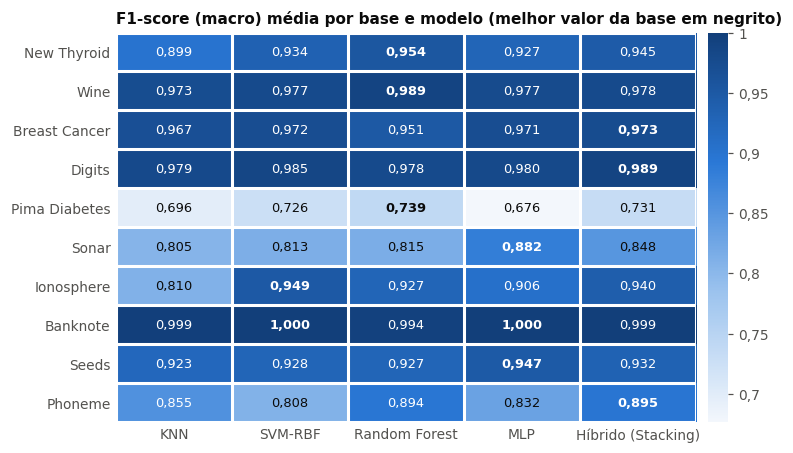

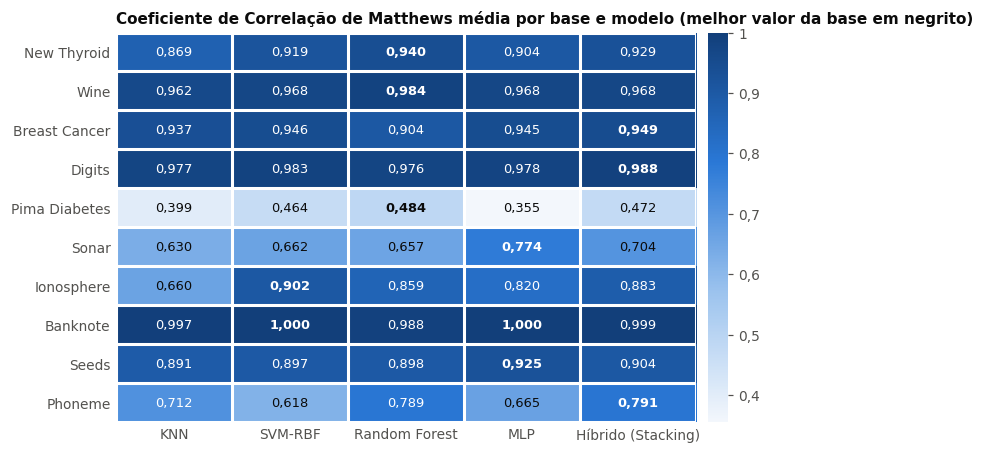

In [12]:
# Estilo comum das figuras: fundo claro, grade discreta, texto em tons neutros.
COR_TEXTO, COR_TEXTO_SEC, COR_GRADE = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.edgecolor": COR_GRADE, "axes.labelcolor": COR_TEXTO_SEC,
    "xtick.color": COR_TEXTO_SEC, "ytick.color": COR_TEXTO_SEC, "text.color": COR_TEXTO,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "grid.color": COR_GRADE, "grid.linewidth": 0.8,
})
# Escala sequencial de um único matiz (claro -> escuro) para os mapas de calor.
MAPA_SEQUENCIAL = LinearSegmentedColormap.from_list("azul", ["#f3f7fc", "#9cc3ee", "#2a78d6", "#123f7a"])
FIGURAS = {}  # {identificador: caminho do arquivo PNG}
# Rótulos numéricos dos eixos com vírgula decimal (padrão brasileiro).
FORMATO_VIRGULA = FuncFormatter(lambda valor, _: f"{valor:g}".replace(".", ","))


def salvar_figura(fig, identificador: str):
    """Salva a figura em PNG e registra o caminho para uso no PDF."""
    caminho = DIR_SAIDA / f"{identificador}.png"
    fig.savefig(caminho)
    FIGURAS[identificador] = caminho


def figura_mapa_calor(metrica: str):
    """Mapa de calor bases x modelos com a média da métrica nas 10 partições."""
    tabela = tabela_metrica(metrica)
    fig, ax = plt.subplots(figsize=(7.2, 4.6))
    vmin, vmax = tabela.to_numpy().min(), tabela.to_numpy().max()
    imagem = ax.imshow(tabela.to_numpy(), cmap=MAPA_SEQUENCIAL, aspect="auto", vmin=vmin, vmax=vmax)
    ax.set_xticks(range(K_MODELOS), NOMES_MODELOS)
    ax.set_yticks(range(N_BASES), NOMES_BASES)
    ax.tick_params(length=0)
    for lado in ax.spines.values():
        lado.set_visible(False)
    # Linhas brancas separando as células.
    ax.set_xticks(np.arange(-.5, K_MODELOS), minor=True)
    ax.set_yticks(np.arange(-.5, N_BASES), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="minor", length=0)
    melhor = tabela.max(axis=1) if METRICAS[metrica]["maior_melhor"] else tabela.min(axis=1)
    for i in range(N_BASES):
        for j in range(K_MODELOS):
            valor = tabela.iat[i, j]
            claro = (valor - vmin) / (vmax - vmin + 1e-12) > 0.55
            ax.text(j, i, f"{valor:.3f}".replace(".", ","), ha="center", va="center", fontsize=8.5,
                    color="white" if claro else COR_TEXTO,
                    fontweight="bold" if np.isclose(valor, melhor.iloc[i]) else "normal")
    ax.set_title(f"{METRICAS[metrica]['nome']} média por base e modelo (melhor valor da base em negrito)",
                 loc="left")
    barra = fig.colorbar(imagem, ax=ax, fraction=0.035, pad=0.02, format=FORMATO_VIRGULA)
    barra.outline.set_visible(False)
    return fig


for metrica in (METRICA_PRINCIPAL, "mcc"):
    fig = figura_mapa_calor(metrica)
    salvar_figura(fig, f"mapa_calor_{metrica}")
    plt.show()

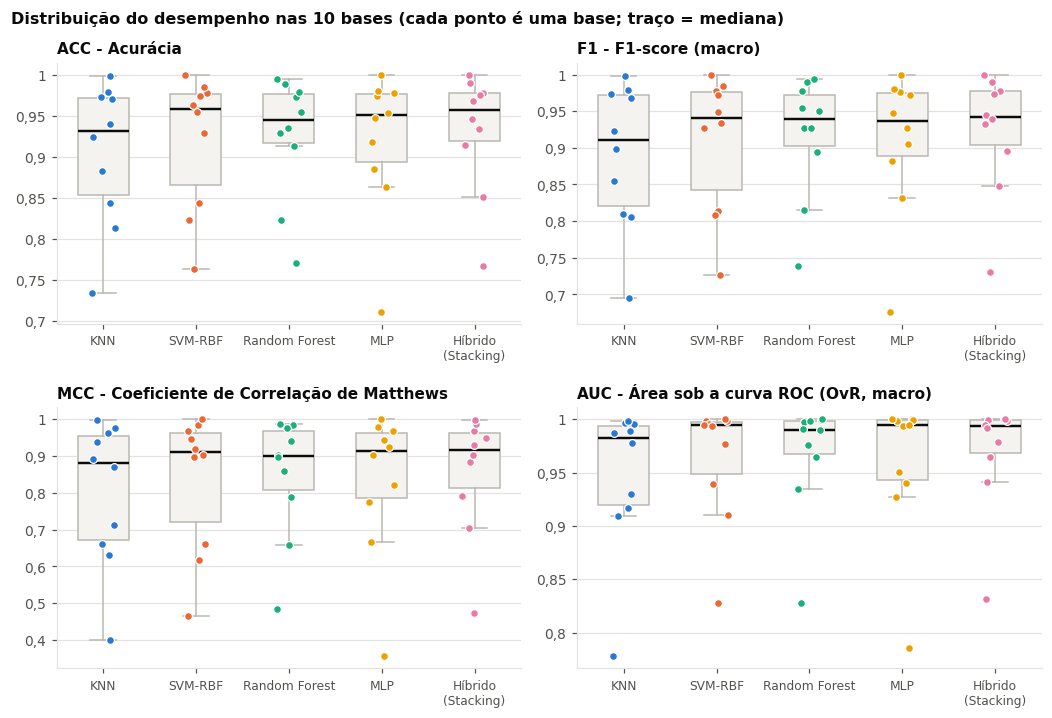

In [13]:
def figura_distribuicoes(metricas=("acuracia", "f1_macro", "mcc", "auc_roc")):
    """Distribuição do desempenho de cada modelo nas 10 bases (um painel por métrica)."""
    fig, eixos = plt.subplots(2, 2, figsize=(9.6, 6.6), sharey=False)
    gerador = np.random.default_rng(SEMENTE)
    for ax, metrica in zip(eixos.ravel(), metricas):
        tabela = tabela_metrica(metrica)
        for j, modelo in enumerate(NOMES_MODELOS):
            valores = tabela[modelo].to_numpy()
            # Caixa (quartis) em cinza discreto + pontos (um por base) na cor do modelo.
            ax.boxplot(valores, positions=[j], widths=0.55, showfliers=False, patch_artist=True,
                       boxprops=dict(facecolor="#f4f3f0", edgecolor="#b9b8b2"),
                       medianprops=dict(color=COR_TEXTO, linewidth=1.6),
                       whiskerprops=dict(color="#b9b8b2"), capprops=dict(color="#b9b8b2"))
            ax.scatter(j + gerador.uniform(-0.14, 0.14, len(valores)), valores, s=26,
                       color=CORES_MODELOS[modelo], edgecolor="white", linewidth=0.8, zorder=3)
        ax.set_xticks(range(K_MODELOS), [m.replace(" (", "\n(") for m in NOMES_MODELOS], fontsize=8)
        ax.set_title(f"{METRICAS[metrica]['sigla']} - {METRICAS[metrica]['nome']}", loc="left")
        ax.yaxis.set_major_formatter(FORMATO_VIRGULA)
        ax.yaxis.grid(True)
        ax.set_axisbelow(True)
    fig.suptitle("Distribuição do desempenho nas 10 bases (cada ponto é uma base; traço = mediana)",
                 x=0.01, ha="left", fontsize=10.5, fontweight="bold")
    fig.tight_layout(h_pad=1.6)
    return fig


fig = figura_distribuicoes()
salvar_figura(fig, "distribuicoes")
plt.show()

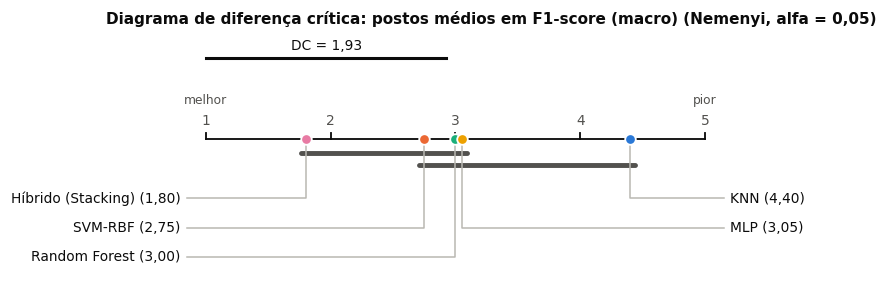

In [14]:
def figura_diferenca_critica(metrica: str):
    """Diagrama de diferença crítica (Demšar, 2006) para os postos médios de uma métrica.

    Modelos ligados por uma barra horizontal NÃO diferem significativamente
    entre si pelo teste de Nemenyi (diferença de postos menor que a DC).
    """
    postos = POSTOS_MEDIOS[metrica].sort_values()
    nomes, valores = list(postos.index), postos.to_numpy()
    fig, ax = plt.subplots(figsize=(8.2, 2.9))
    ax.set_xlim(0.2, K_MODELOS + 0.8)
    ax.axis("off")
    # Eixo dos postos.
    ax.plot([1, K_MODELOS], [0, 0], color=COR_TEXTO, linewidth=1.2)
    for p in range(1, K_MODELOS + 1):
        ax.plot([p, p], [0, 0.08], color=COR_TEXTO, linewidth=1.2)
        ax.text(p, 0.14, str(p), ha="center", va="bottom", fontsize=9, color=COR_TEXTO_SEC)
    ax.text(1, 0.42, "melhor", ha="center", fontsize=8, color=COR_TEXTO_SEC)
    ax.text(K_MODELOS, 0.42, "pior", ha="center", fontsize=8, color=COR_TEXTO_SEC)
    # Barra de referência com o tamanho da diferença crítica.
    ax.plot([1, 1 + DIFERENCA_CRITICA], [0.95, 0.95], color=COR_TEXTO, linewidth=2)
    ax.text(1 + DIFERENCA_CRITICA / 2, 1.02, f"DC = {DIFERENCA_CRITICA:.2f}".replace(".", ","),
            ha="center", va="bottom", fontsize=9)
    # Grupos (cliques) de modelos sem diferença significativa: intervalos maximais.
    grupos = []
    for i in range(K_MODELOS):
        j = max(t for t in range(i, K_MODELOS) if valores[t] - valores[i] < DIFERENCA_CRITICA)
        if j > i and not any(a <= i and j <= b for a, b in grupos):
            grupos.append((i, j))
    for g, (i, j) in enumerate(grupos):
        y = -0.16 - 0.14 * g
        ax.plot([valores[i] - 0.04, valores[j] + 0.04], [y, y], color="#52514e", linewidth=3.2,
                solid_capstyle="round")
    # Rótulos: metade melhor à esquerda, metade pior à direita.
    base_y = -0.16 - 0.14 * len(grupos) - 0.25
    metade = (K_MODELOS + 1) // 2
    ax.set_ylim(base_y - 0.34 * (metade - 1) - 0.25, 1.25)
    for i, (nome, valor) in enumerate(zip(nomes, valores)):
        esquerda = i < metade
        y = base_y - 0.34 * (i if esquerda else K_MODELOS - 1 - i)
        x_texto = 0.85 if esquerda else K_MODELOS + 0.15
        ax.plot([valor, valor, x_texto], [0, y, y], color="#b9b8b2", linewidth=1)
        ax.scatter([valor], [0], s=48, color=CORES_MODELOS[nome], edgecolor="white", linewidth=1.2, zorder=3)
        rotulo = f"{nome} ({valor:.2f})".replace(".", ",")
        ax.text(x_texto + (-0.05 if esquerda else 0.05), y, rotulo, va="center",
                ha="right" if esquerda else "left", fontsize=9)
    ax.set_title(f"Diagrama de diferença crítica: postos médios em {METRICAS[metrica]['nome']} "
                 f"(Nemenyi, alfa = {ALFA})".replace(".", ","), loc="left")
    return fig


fig = figura_diferenca_critica(METRICA_PRINCIPAL)
salvar_figura(fig, "diferenca_critica")
plt.show()

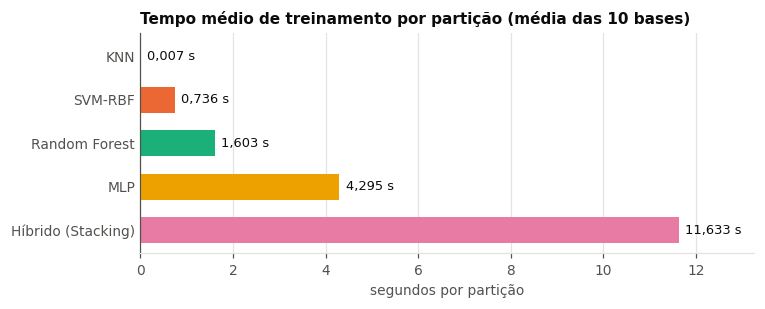

In [15]:
def figura_tempo():
    """Tempo médio de treinamento por partição (média entre as 10 bases)."""
    tempos = RESUMO_GERAL["tempo_treino"]
    fig, ax = plt.subplots(figsize=(7.2, 2.6))
    posicoes = np.arange(K_MODELOS)[::-1]
    ax.barh(posicoes, tempos.to_numpy(), height=0.6, color=[CORES_MODELOS[m] for m in NOMES_MODELOS])
    ax.set_yticks(posicoes, NOMES_MODELOS)
    ax.tick_params(axis="y", length=0)
    for y, valor in zip(posicoes, tempos.to_numpy()):
        ax.text(valor + tempos.max() * 0.012, y, f"{valor:.3f} s".replace(".", ","), va="center", fontsize=8.5)
    ax.set_xlim(0, tempos.max() * 1.14)
    ax.set_xlabel("segundos por partição")
    ax.xaxis.set_major_formatter(FORMATO_VIRGULA)
    ax.xaxis.grid(True)
    ax.set_axisbelow(True)
    ax.spines["left"].set_color(COR_TEXTO_SEC)
    ax.set_title("Tempo médio de treinamento por partição (média das 10 bases)", loc="left")
    return fig


fig = figura_tempo()
salvar_figura(fig, "tempo_treino")
plt.show()
registrar_etapa("Geração das figuras")

## 9. Geração do relatório PDF

O relatório é montado com a biblioteca **ReportLab** e contém:

1. Introdução e objetivo
2. Bases de dados
3. Modelos
4. Protocolo experimental
5. Métricas de validação — fórmula, significado, importância e **resultado ideal (com justificativa)**
6. Resultados da comparação
7. Testes de hipótese (Friedman-Nemenyi e ANOVA-Tukey)
8. Discussão e conclusões (texto gerado a partir dos números obtidos)
9. Limitações e referências
10. Apêndice A — tabelas completas (média ± desvio-padrão por base)
11. Apêndice B — ambiente de execução: hardware, software, versões e tempos

Todo o conteúdo numérico do PDF é lido das estruturas calculadas acima; nada é
digitado manualmente. Assim, ao alterar bases, modelos ou sementes e reexecutar
o notebook, o relatório é atualizado de forma coerente.

In [16]:
from xml.sax.saxutils import escape

from reportlab.lib import colors
from reportlab.lib.enums import TA_CENTER, TA_JUSTIFY
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import ParagraphStyle
from reportlab.lib.units import cm
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont
from reportlab.platypus import (Image, KeepTogether, PageBreak, Paragraph,
                                SimpleDocTemplate, Spacer, Table, TableStyle)

# Fonte DejaVu (distribuída com o matplotlib): cobre acentos e símbolos Unicode.
_dir_fontes = Path(matplotlib.get_data_path()) / "fonts" / "ttf"
pdfmetrics.registerFont(TTFont("DejaVu", str(_dir_fontes / "DejaVuSans.ttf")))
pdfmetrics.registerFont(TTFont("DejaVu-Bold", str(_dir_fontes / "DejaVuSans-Bold.ttf")))
pdfmetrics.registerFont(TTFont("DejaVu-Oblique", str(_dir_fontes / "DejaVuSans-Oblique.ttf")))
pdfmetrics.registerFontFamily("DejaVu", normal="DejaVu", bold="DejaVu-Bold",
                              italic="DejaVu-Oblique", boldItalic="DejaVu-Bold")

LARGURA_UTIL = A4[0] - 4 * cm  # margens laterais de 2 cm
AZUL, CINZA_CLARO, CINZA_LINHA = colors.HexColor("#1f4e8c"), colors.HexColor("#f4f3f0"), colors.HexColor("#c9c8c2")

# Estilos de parágrafo.
E_TITULO = ParagraphStyle("titulo", fontName="DejaVu-Bold", fontSize=20, leading=25, alignment=TA_CENTER,
                          textColor=AZUL, spaceAfter=10)
E_SUBTITULO = ParagraphStyle("subtitulo", fontName="DejaVu", fontSize=12, leading=16, alignment=TA_CENTER,
                             textColor=colors.HexColor("#52514e"))
E_H1 = ParagraphStyle("h1", fontName="DejaVu-Bold", fontSize=13.5, leading=17, textColor=AZUL,
                      spaceBefore=14, spaceAfter=6, keepWithNext=True)
E_H2 = ParagraphStyle("h2", fontName="DejaVu-Bold", fontSize=10.5, leading=14, spaceBefore=10, spaceAfter=3, keepWithNext=True)
E_TEXTO = ParagraphStyle("texto", fontName="DejaVu", fontSize=9.2, leading=13.2, alignment=TA_JUSTIFY,
                         spaceAfter=5)
E_LEGENDA = ParagraphStyle("legenda", fontName="DejaVu-Oblique", fontSize=8, leading=10.5,
                           textColor=colors.HexColor("#52514e"), spaceBefore=3, spaceAfter=9)
E_CELULA = ParagraphStyle("celula", fontName="DejaVu", fontSize=7.6, leading=9.6)
E_CELULA_CAB = ParagraphStyle("celula_cab", parent=E_CELULA, fontName="DejaVu-Bold", textColor=colors.white)


def num(valor, casas=3) -> str:
    """Formata um número com vírgula decimal (padrão brasileiro)."""
    return f"{valor:.{casas}f}".replace(".", ",")


def p_valor(p) -> str:
    """Formata um p-valor, evitando exibir zero."""
    return "< 0,001" if p < 0.001 else num(p, 3)


def P(texto, estilo=E_TEXTO):
    """Atalho para criar um parágrafo."""
    return Paragraph(texto, estilo)


def tabela_pdf(dados, larguras, negrito=(), alinhar_centro_desde=1, repetir_cabecalho=True):
    """Cria uma tabela formatada. A primeira linha de ``dados`` é o cabeçalho.

    ``negrito`` é uma coleção de pares (linha, coluna) a destacar em negrito
    (índices relativos ao corpo da tabela, isto é, sem contar o cabeçalho).
    """
    negrito = set(negrito)
    linhas = [[Paragraph(escape(str(c)), E_CELULA_CAB) for c in dados[0]]]
    for i, linha in enumerate(dados[1:]):
        linhas.append([Paragraph(f"<b>{escape(str(c))}</b>" if (i, j) in negrito else escape(str(c)), E_CELULA)
                       for j, c in enumerate(linha)])
    tabela = Table(linhas, colWidths=larguras, repeatRows=1 if repetir_cabecalho else 0)
    tabela.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), AZUL),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1), [colors.white, CINZA_CLARO]),
        ("LINEBELOW", (0, 0), (-1, -1), 0.4, CINZA_LINHA),
        ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
        ("TOPPADDING", (0, 0), (-1, -1), 3), ("BOTTOMPADDING", (0, 0), (-1, -1), 3),
        ("LEFTPADDING", (0, 0), (-1, -1), 4), ("RIGHTPADDING", (0, 0), (-1, -1), 4),
    ]))
    return tabela


def imagem_pdf(caminho, largura=LARGURA_UTIL):
    """Insere uma figura PNG preservando a proporção."""
    from matplotlib.image import imread
    altura_px, largura_px = imread(caminho).shape[:2]
    return Image(str(caminho), width=largura, height=largura * altura_px / largura_px)


def formula_pdf(latex: str, altura_fonte=13):
    """Renderiza uma fórmula (mathtext do matplotlib) como imagem para o PDF."""
    fig = plt.figure(figsize=(0.1, 0.1))
    fig.text(0, 0, latex, fontsize=altura_fonte, color="#0b0b0b")
    memoria = io.BytesIO()
    fig.savefig(memoria, format="png", dpi=220, bbox_inches="tight", pad_inches=0.04, transparent=True)
    plt.close(fig)
    memoria.seek(0)
    from matplotlib.image import imread
    altura_px, largura_px = imread(io.BytesIO(memoria.getvalue())).shape[:2]
    escala = 72 / 220  # pixels -> pontos
    imagem = Image(memoria, width=largura_px * escala, height=altura_px * escala)
    imagem.hAlign = "LEFT"
    return imagem

In [17]:
def texto_discussao() -> list:
    """Gera os parágrafos de discussão a partir dos resultados calculados."""
    m = METRICA_PRINCIPAL
    nome_m = METRICAS[m]["nome"]
    postos = POSTOS_MEDIOS[m].sort_values()
    medias = RESUMO_GERAL[m]
    melhor, pior = postos.index[0], postos.index[-1]
    fr = FRIEDMAN.loc[m]
    paragrafos = []

    # (a) Ordenação geral.
    ordem = "; ".join(f"{nome} (posto médio {num(v, 2)}; média {num(medias[nome])})" for nome, v in postos.items())
    paragrafos.append(
        f"<b>Ordenação geral.</b> Considerando a métrica principal ({escape(nome_m)}), a ordenação dos modelos "
        f"pelo posto médio nas {N_BASES} bases foi: {escape(ordem)}. O modelo <b>{escape(melhor)}</b> obteve o "
        f"melhor posto médio e o modelo {escape(pior)}, o pior. Em número de bases em que cada modelo foi o "
        f"melhor (empates contam para todos): "
        + escape("; ".join(f"{n}: {int(VITORIAS.loc[n, m])}" for n in NOMES_MODELOS)) + ".")

    # (b) Testes de hipótese: Friedman-Nemenyi e ANOVA-Tukey.
    an = ANOVA.loc[m]
    rej_f, rej_a = fr["p_friedman"] < ALFA, an["p_anova"] < ALFA

    def _lista(pares):
        return escape("; ".join(f"{a} superior a {b}" for a, b in pares)) if pares else "nenhum par"

    paragrafos.append(
        f"<b>Friedman-Nemenyi.</b> O teste de Friedman {'rejeitou' if rej_f else 'não rejeitou'} a hipótese de "
        f"desempenhos iguais em {escape(nome_m)} (qui-quadrado = {num(fr['qui2'], 2)}; p = {p_valor(fr['p_friedman'])}; "
        f"Iman-Davenport: F = {num(fr['F_ID'], 2)}; p = {p_valor(fr['p_ID'])}). "
        + (f"Pelo pós-teste de Nemenyi (DC = {num(DIFERENCA_CRITICA, 2)}), os pares com diferença significativa "
           f"são: {_lista(PARES_NEMENYI)}." if rej_f else
           "Como o teste global não foi significativo, o pós-teste de Nemenyi não é interpretado."))
    paragrafos.append(
        f"<b>ANOVA-Tukey.</b> A ANOVA em blocos {'rejeitou' if rej_a else 'não rejeitou'} a hipótese de médias "
        f"iguais (F({int(an['gl_modelos'])}; {int(an['gl_residuo'])}) = {num(an['F'], 2)}; p = {p_valor(an['p_anova'])}). "
        + (f"Pelo pós-teste de Tukey (HSD = {num(an['HSD'], 4)}), os pares com diferença significativa são: "
           f"{_lista(PARES_TUKEY)}. " if rej_a else
           "Como o teste global não foi significativo, o pós-teste de Tukey não é interpretado. ")
        + f"O teste de Shapiro-Wilk sobre os resíduos resultou em p = {p_valor(an['p_shapiro'])}: "
        + ("não há evidência contra a normalidade, de modo que a suposição da ANOVA é aceitável."
           if an["residuos_normais"] else
           "a normalidade dos resíduos é rejeitada, portanto a suposição da ANOVA é violada e o resultado "
           "paramétrico deve ser lido com cautela, prevalecendo o não paramétrico."))
    if rej_f == rej_a and set(PARES_NEMENYI) == set(PARES_TUKEY):
        concord = ("Os dois procedimentos chegaram à mesma decisão global e aos mesmos pares significativos, "
                   "o que reforça a conclusão.")
    elif rej_f == rej_a:
        concord = ("Os dois procedimentos chegaram à mesma decisão global, mas diferem nos pares apontados pelos "
                   "pós-testes; apenas os pares apontados por ambos devem ser tomados como diferenças seguras.")
    else:
        concord = ("Os dois procedimentos divergem na decisão global. O teste de Friedman compara postos e não "
                   "depende de normalidade, enquanto a ANOVA compara médias e é sensível a bases com valores "
                   "extremos; a divergência indica que a evidência de diferença entre os modelos não é robusta.")
    n_conc = int((FRIEDMAN["significativo"] == ANOVA["significativo"]).sum())
    paragrafos.append(
        f"<b>Concordância entre os testes.</b> {concord} Considerando as {len(METRICAS_QUALIDADE)} métricas de "
        f"qualidade, Friedman foi significativo em {int(FRIEDMAN['significativo'].sum())}, a ANOVA em "
        f"{int(ANOVA['significativo'].sum())}, e as duas decisões coincidiram em {n_conc}. A normalidade dos "
        f"resíduos foi aceita em {int(ANOVA['residuos_normais'].sum())} das {len(METRICAS_QUALIDADE)} métricas.")

    # (c) Consistência entre métricas.
    lideres = POSTOS_MEDIOS.idxmin(axis=0)
    contagem = lideres.value_counts()
    paragrafos.append(
        f"<b>Consistência entre métricas.</b> O melhor posto médio coube a: "
        + escape("; ".join(f"{modelo} em {qtd} métrica(s)" for modelo, qtd in contagem.items()))
        + ". Quando o líder muda conforme a métrica, a escolha do modelo deve considerar o que é mais "
          "importante na aplicação: a decisão final (acurácia, F1, MCC) ou a qualidade das probabilidades "
          "(AUC, perda logarítmica).")

    # (d) Modelo híbrido e custo computacional.
    hib = "Híbrido (Stacking)"
    if hib in NOMES_MODELOS:
        posicao = list(postos.index).index(hib) + 1
        tempos = RESUMO_GERAL["tempo_treino"]
        individuais = [n for n in NOMES_MODELOS if n != hib]
        melhor_ind = min(individuais, key=lambda n: POSTOS_MEDIOS.loc[n, m])
        dif = medias[hib] - medias[melhor_ind]
        paragrafos.append(
            f"<b>Modelo híbrido e custo computacional.</b> O modelo híbrido ficou na {posicao}ª posição em "
            f"{escape(nome_m)} (posto médio {num(postos[hib], 2)}). Em relação ao melhor modelo individual "
            f"por posto médio ({escape(melhor_ind)}), a diferença de {escape(nome_m)} médio foi de "
            f"{'+' if dif >= 0 else '-'}{num(abs(dif), 4)}. O tempo médio de treinamento do híbrido foi de "
            f"{num(tempos[hib], 3)} s por partição, contra {num(tempos[melhor_ind], 3)} s do {escape(melhor_ind)} "
            f"(razão de {num(tempos[hib] / tempos[melhor_ind], 1)} vezes). O custo maior é esperado, pois o "
            f"Stacking treina cada modelo-base {N_FOLDS_INTERNOS + 1} vezes; cabe avaliar se o ganho obtido "
            f"justifica esse custo na aplicação pretendida.")

    # (e) Bases mais difíceis e mais fáceis.
    media_base = tabela_metrica(m).mean(axis=1).sort_values()
    paragrafos.append(
        f"<b>Dificuldade das bases.</b> As bases com menor {escape(nome_m)} médio entre os modelos foram "
        f"{escape(media_base.index[0])} ({num(media_base.iloc[0])}) e {escape(media_base.index[1])} "
        f"({num(media_base.iloc[1])}); as de maior valor foram {escape(media_base.index[-1])} "
        f"({num(media_base.iloc[-1])}) e {escape(media_base.index[-2])} ({num(media_base.iloc[-2])}). "
        f"Nas bases mais fáceis os modelos praticamente empatam; é nas mais difíceis que as diferenças "
        f"entre os algoritmos se tornam visíveis.")
    return paragrafos

In [18]:
def gerar_relatorio_pdf(caminho=ARQUIVO_PDF):
    """Monta e grava o relatório PDF com a comparação dos modelos."""
    h = []  # lista de elementos ("história") do documento
    siglas = [METRICAS[m]["sigla"] for m in METRICAS]

    # ------------------------------------------------------------------ Capa
    h += [Spacer(1, 5.5 * cm),
          P("Avaliação comparativa de modelos de Machine Learning para Reconhecimento de Padrões", E_TITULO),
          P(f"{K_MODELOS} modelos (sendo 1 híbrido) avaliados em {N_BASES} bases de dados públicas", E_SUBTITULO),
          Spacer(1, 1.2 * cm),
          P("Disciplina: Reconhecimento de Padrões", E_SUBTITULO),
          P("Pós-Graduação em Engenharia da Computação", E_SUBTITULO),
          Spacer(1, 7 * cm),
          P(f"Relatório gerado automaticamente em {datetime.now():%d/%m/%Y %H:%M}", E_SUBTITULO),
          PageBreak()]

    # ------------------------------------------------------------ 1. Introdução
    h += [P("1. Introdução e objetivo", E_H1),
          P(f"Este relatório apresenta a comparação experimental de {K_MODELOS} modelos de aprendizado de máquina "
            f"usados em reconhecimento de padrões: {escape(', '.join(NOMES_MODELOS[:-1]))} e um modelo híbrido, "
            f"{escape(NOMES_MODELOS[-1])}. Os modelos foram avaliados em {N_BASES} bases de dados públicas de "
            f"classificação, sob o mesmo protocolo de validação cruzada, e comparados por "
            f"{len(METRICAS_QUALIDADE)} métricas de qualidade preditiva, pelo tempo de treinamento e por dois "
            f"procedimentos de teste de hipótese: Friedman-Nemenyi (não paramétrico) e ANOVA-Tukey (paramétrico)."),
          P("O objetivo é responder a três perguntas: (i) qual modelo apresenta, em média, o melhor desempenho; "
            "(ii) se as diferenças observadas são estatisticamente significativas; e (iii) se o modelo híbrido "
            "traz ganho que compense seu custo computacional.")]

    # -------------------------------------------------------- 2. Bases de dados
    h += [P("2. Bases de dados", E_H1),
          P("As bases foram escolhidas por serem públicas, amplamente utilizadas como referência na literatura e "
            "por diferirem em domínio de aplicação, número de instâncias, dimensionalidade, número de classes e "
            "balanceamento. Todas têm atributos numéricos e não possuem valores ausentes codificados. "
            "A coluna Desb. é a razão entre o número de exemplos da classe majoritária e o da minoritária "
            "(1,00 = perfeitamente balanceada).")]
    dados = [["Base", "Domínio", "Inst.", "Atrib.", "Classes", "Desb.", "Repositório de origem"]]
    for _, r in RESUMO_BASES.iterrows():
        dados.append([r["Base"], r["Domínio"], r["Instâncias"], r["Atributos"], r["Classes"],
                      num(r["Desbalanceamento"], 2), f"{r['Origem']}; acesso via {r['Acesso']}"])
    h += [tabela_pdf(dados, [2.4 * cm, 3.9 * cm, 1.1 * cm, 1.2 * cm, 1.6 * cm, 1.2 * cm, 5.6 * cm]),
          P("Tabela 1 - Características das bases de dados utilizadas.", E_LEGENDA)]

    # --------------------------------------------------------------- 3. Modelos
    h += [P("3. Modelos avaliados", E_H1),
          P("Foram selecionados quatro classificadores individuais de famílias distintas (baseado em distância, "
            "em margem, em comitê de árvores e em redes neurais) e um modelo híbrido, que combina três deles em "
            "uma arquitetura de dois níveis (stacking). Os hiperparâmetros são fixos e iguais para todas as bases.")]
    dados = [["Modelo", "Princípio de funcionamento", "Configuração adotada"]]
    dados += [[n, DESCRICAO_MODELOS[n][0], DESCRICAO_MODELOS[n][1]] for n in NOMES_MODELOS]
    h += [tabela_pdf(dados, [2.8 * cm, 8.6 * cm, 5.6 * cm]),
          P("Tabela 2 - Modelos avaliados e respectivas configurações.", E_LEGENDA)]
    h += [P("3.1 Motivo da seleção de cada modelo", E_H2),
          P("O critério geral foi cobrir paradigmas de aprendizado diferentes, de modo que a comparação contraste "
            "formas distintas de reconhecer padrões, e não variações de uma mesma ideia. Os motivos específicos são:")]
    h += [P(f"<b>{escape(n)}.</b> {escape(MOTIVO_MODELOS[n])}") for n in NOMES_MODELOS]

    # ------------------------------------------------------------- 4. Protocolo
    h += [P("4. Protocolo experimental", E_H1),
          P(f"<b>Validação.</b> Validação cruzada estratificada com {N_FOLDS} partições: cada base é dividida em "
            f"{N_FOLDS} partes que preservam a proporção das classes; cada parte serve uma vez como teste e as "
            f"demais como treino. As partições são geradas uma única vez por base (semente {SEMENTE}) e usadas "
            f"por todos os modelos, o que torna a comparação pareada."),
          P("<b>Pré-processamento.</b> Padronização dos atributos (média zero e desvio-padrão unitário) para os "
            "modelos sensíveis à escala (KNN, SVM e MLP). A padronização é ajustada apenas com os dados de treino "
            "de cada partição, dentro de um pipeline, para evitar vazamento de informação do teste."),
          P(f"<b>Agregação.</b> Para cada par base-modelo calcula-se a média e o desvio-padrão das métricas nas "
            f"{N_FOLDS} partições. No total foram realizadas {len(RESULTADOS)} avaliações "
            f"({N_BASES} bases x {K_MODELOS} modelos x {N_FOLDS} partições), em {num(TEMPO_TOTAL / 60, 1)} minutos. "
            f"O hardware, o software e os tempos desta execução estão descritos no Apêndice B."),
          P(f"<b>Testes de hipótese.</b> As médias por base são comparadas por dois procedimentos, ao nível de "
            f"significância de {num(ALFA, 2)}: Friedman com pós-teste de Nemenyi (Demšar, 2006), baseado em postos, e "
            f"ANOVA em blocos casualizados com pós-teste de Tukey HSD, baseado em médias. Em ambos, cada base é um "
            f"bloco, pois todos os modelos são avaliados nas mesmas bases.")]

    # -------------------------------------------------------------- 5. Métricas
    h += [P("5. Métricas de validação", E_H1),
          P("Esta seção descreve cada métrica utilizada: o que ela mede, por que é importante e qual é o seu "
            "resultado ideal. Notação: VP = verdadeiros positivos, VN = verdadeiros negativos, FP = falsos "
            "positivos, FN = falsos negativos, K = número de classes, N = número de exemplos. Nas métricas "
            "macro, o índice k indica que a quantidade é calculada tratando a classe k como positiva e as "
            "demais como negativas; o resultado final é a média simples entre as classes.")]
    dados = [["Métrica", "Sigla", "Intervalo", "Valor ideal", "Sentido"]]
    dados += [[d["nome"], d["sigla"], d["intervalo"].replace("+inf", "+∞"), d["ideal"],
               "maior é melhor" if d["maior_melhor"] else "menor é melhor"] for d in METRICAS.values()]
    h += [tabela_pdf(dados, [6.6 * cm, 2.2 * cm, 2.4 * cm, 2.9 * cm, 2.9 * cm]),
          P("Tabela 3 - Resumo das métricas: intervalo de valores, valor ideal e sentido de otimização.", E_LEGENDA)]
    for i, d in enumerate(METRICAS.values(), start=1):
        bloco = [P(f"5.{i} {escape(d['nome'])} ({escape(d['sigla'])})", E_H2)]
        if d["formula"]:
            bloco += [formula_pdf(d["formula"]), Spacer(1, 3)]
        bloco += [P(f"<b>Significado.</b> {escape(d['significado'])}"),
                  P(f"<b>Importância.</b> {escape(d['importancia'])}"),
                  P(f"<b>Resultado ideal: {escape(d['ideal'])}.</b> {escape(d['porque'])}")]
        h.append(KeepTogether(bloco))

    # ------------------------------------------------------------ 6. Resultados
    h += [PageBreak(), P("6. Resultados da comparação", E_H1),
          P(f"A Tabela 4 resume o desempenho de cada modelo pela média de cada métrica nas {N_BASES} bases. "
            f"O melhor valor de cada coluna está em negrito (o maior, exceto para LogLoss e Tempo, em que o "
            f"menor é melhor). As tabelas completas, por base e com desvio-padrão, estão no Apêndice.")]
    dados, destaque = [["Modelo"] + siglas], []
    for i, n in enumerate(NOMES_MODELOS):
        dados.append([n] + [num(RESUMO_GERAL.loc[n, m], 3) for m in METRICAS])
    for j, m in enumerate(METRICAS, start=1):
        col = RESUMO_GERAL[m]
        alvo = col.max() if METRICAS[m]["maior_melhor"] else col.min()
        destaque += [(i, j) for i, n in enumerate(NOMES_MODELOS) if np.isclose(col[n], alvo)]
    h += [tabela_pdf(dados, [2.8 * cm] + [1.35 * cm] * (len(METRICAS) - 2) + [1.7 * cm, 1.6 * cm], negrito=destaque),
          P(f"Tabela 4 - Média de cada métrica nas {N_BASES} bases, por modelo.", E_LEGENDA),
          imagem_pdf(FIGURAS[f"mapa_calor_{METRICA_PRINCIPAL}"], LARGURA_UTIL * 0.88),
          P(f"Figura 1 - {METRICAS[METRICA_PRINCIPAL]['nome']} médio ({N_FOLDS} partições) de cada modelo em cada base. "
            f"Tons mais escuros indicam valores maiores.", E_LEGENDA),
          imagem_pdf(FIGURAS["mapa_calor_mcc"], LARGURA_UTIL * 0.88),
          P("Figura 2 - Coeficiente de Correlação de Matthews médio de cada modelo em cada base.", E_LEGENDA),
          imagem_pdf(FIGURAS["distribuicoes"], LARGURA_UTIL * 0.92),
          P(f"Figura 3 - Distribuição do desempenho de cada modelo nas {N_BASES} bases. Cada ponto é o valor médio "
            f"em uma base; a caixa indica os quartis e o traço, a mediana. As escalas verticais diferem entre os painéis.",
            E_LEGENDA),
          imagem_pdf(FIGURAS["tempo_treino"], LARGURA_UTIL * 0.85),
          P("Figura 4 - Tempo médio de treinamento por partição. Valores dependentes do hardware; "
            "úteis apenas para comparação relativa.", E_LEGENDA)]

    # ------------------------------------------------------ 7. Testes de hipótese
    mp = METRICAS[METRICA_PRINCIPAL]
    siglas_q = [METRICAS[m]["sigla"] for m in METRICAS_QUALIDADE]
    h += [PageBreak(), P("7. Testes de hipótese", E_H1),
          P(f"Diferenças entre médias podem ocorrer por acaso. Para verificar se os modelos realmente diferem, "
            f"aplicam-se dois procedimentos, cada um composto por um teste global e um pós-teste de comparações "
            f"múltiplas. A unidade de análise é a média de cada métrica em cada base (matriz de {N_BASES} bases por "
            f"{K_MODELOS} modelos). Nos dois testes globais as hipóteses são as mesmas: H0, todos os modelos têm o "
            f"mesmo desempenho; H1, ao menos um modelo difere. Rejeita-se H0 quando o p-valor é menor que "
            f"α = {num(ALFA, 2)}; o p-valor é a probabilidade de observar diferenças tão grandes quanto as obtidas "
            f"se H0 fosse verdadeira. O pós-teste só é interpretado quando o teste global rejeita H0, e indica "
            f"quais pares de modelos diferem, controlando o erro acumulado das {len(PARES_MODELOS)} comparações."),
          P("Usar os dois procedimentos é uma forma de verificação cruzada: o Friedman-Nemenyi não exige "
            "normalidade, mas descarta a magnitude das diferenças; a ANOVA-Tukey aproveita a magnitude e tende a "
            "ter mais poder, mas depende de suposições que nem sempre valem para métricas limitadas a [0, 1]."),

          P("7.1 Friedman-Nemenyi (não paramétrico)", E_H2),
          formula_pdf(r"$\chi^2_F=\frac{12N}{k(k+1)}\left[\sum_{j=1}^{k}R_j^2-\frac{k(k+1)^2}{4}\right]"
                      r"\qquad DC=q_\alpha\sqrt{\frac{k(k+1)}{6N}}$"), Spacer(1, 3),
          P(f"Em cada base, os modelos recebem postos de 1 (melhor) a {K_MODELOS} (pior); empates recebem o posto "
            f"médio. O teste de Friedman verifica se os postos médios R_j dos k modelos nas N bases são iguais; a "
            f"estatística de Iman-Davenport (F) é uma correção menos conservadora do mesmo teste. No pós-teste de "
            f"Nemenyi, dois modelos diferem quando a diferença entre seus postos médios é de pelo menos a diferença "
            f"crítica DC. A Tabela 5 traz os postos médios: quanto menor, melhor; o ideal seria 1,00 (melhor modelo "
            f"em todas as bases).")]
    dados = [["Modelo"] + siglas_q]
    dados += [[n] + [num(POSTOS_MEDIOS.loc[n, m], 2) for m in METRICAS_QUALIDADE] for n in NOMES_MODELOS]
    destaque = [(i, j) for j, m in enumerate(METRICAS_QUALIDADE, start=1) for i, n in enumerate(NOMES_MODELOS)
                if np.isclose(POSTOS_MEDIOS.loc[n, m], POSTOS_MEDIOS[m].min())]
    h += [tabela_pdf(dados, [3.5 * cm] + [1.45 * cm] * (len(METRICAS_QUALIDADE) - 1) + [1.8 * cm], negrito=destaque),
          P("Tabela 5 - Posto médio dos modelos por métrica (1 = melhor). Melhor posto de cada coluna em negrito.",
            E_LEGENDA)]
    dados = [["Métrica", "Qui-quadrado", "p (Friedman)", "F (Iman-Davenport)", "p (I-D)", "Rejeita H0?"]]
    for m in METRICAS_QUALIDADE:
        r = FRIEDMAN.loc[m]
        dados.append([METRICAS[m]["nome"], num(r["qui2"], 2), p_valor(r["p_friedman"]), num(r["F_ID"], 2),
                      p_valor(r["p_ID"]), "sim" if r["significativo"] else "não"])
    h += [tabela_pdf(dados, [5.8 * cm, 2.4 * cm, 2.1 * cm, 3.1 * cm, 1.5 * cm, 2.1 * cm]),
          P(f"Tabela 6 - Teste de Friedman por métrica (k = {K_MODELOS} modelos, N = {N_BASES} bases, "
            f"α = {num(ALFA, 2)}). Diferença crítica de Nemenyi: DC = {num(DIFERENCA_CRITICA, 3)}.", E_LEGENDA),
          imagem_pdf(FIGURAS["diferenca_critica"], LARGURA_UTIL * 0.95),
          P(f"Figura 5 - Diagrama de diferença crítica (Nemenyi) para {mp['nome']}. Modelos ligados por uma barra "
            f"horizontal não diferem significativamente entre si.", E_LEGENDA),

          P("7.2 ANOVA-Tukey (paramétrico)", E_H2),
          formula_pdf(r"$F=\frac{QM_{modelos}}{QM_{res}}=\frac{SQ_{modelos}/(k-1)}{SQ_{res}/[(k-1)(N-1)]}"
                      r"\qquad HSD=q_{\alpha;\,k;\,gl}\sqrt{\frac{QM_{res}}{N}}$"), Spacer(1, 3),
          P("A análise de variância (ANOVA) em blocos casualizados decompõe a variação total da métrica em três "
            "parcelas: entre modelos (tratamentos), entre bases (blocos) e resíduo. A estatística F é a razão entre "
            "o quadrado médio dos modelos e o do resíduo: valores muito maiores que 1 indicam que os modelos "
            "diferem mais do que o ruído explicaria. Tratar as bases como blocos remove da comparação a diferença "
            "de dificuldade entre elas (equivale a uma ANOVA de medidas repetidas com um fator); uma ANOVA de um "
            "fator simples trataria as bases como réplicas independentes e perderia poder."),
          P("No pós-teste de Tukey (HSD, diferença honestamente significativa), dois modelos diferem quando a "
            "diferença entre suas médias é de pelo menos HSD, calculada com o quantil q da amplitude studentizada. "
            "A ANOVA supõe resíduos com distribuição normal e variância homogênea; a normalidade é verificada pelo "
            "teste de Shapiro-Wilk (H0: os resíduos são normais), de modo que, nesse teste, o desejável é não "
            "rejeitar H0 (p maior ou igual a α).")]
    dados = [["Métrica", "F", "p (ANOVA)", "Rejeita H0?", "QM resíduo", "HSD (Tukey)", "p (Shapiro)", "Resíduos normais?"]]
    for m in METRICAS_QUALIDADE:
        r = ANOVA.loc[m]
        dados.append([METRICAS[m]["nome"], num(r["F"], 2), p_valor(r["p_anova"]), "sim" if r["significativo"] else "não",
                      num(r["QM_residuo"], 5), num(r["HSD"], 4), p_valor(r["p_shapiro"]),
                      "sim" if r["residuos_normais"] else "não"])
    h += [tabela_pdf(dados, [4.9 * cm, 1.2 * cm, 1.7 * cm, 1.6 * cm, 1.9 * cm, 1.9 * cm, 1.9 * cm, 1.9 * cm]),
          P(f"Tabela 7 - ANOVA em blocos casualizados por métrica, com {int(ANOVA['gl_modelos'].iloc[0])} e "
            f"{int(ANOVA['gl_residuo'].iloc[0])} graus de liberdade, diferença mínima significativa de Tukey e teste "
            f"de normalidade dos resíduos.", E_LEGENDA),

          P(f"7.3 Comparações par a par em {escape(mp['nome'])}", E_H2),
          P(f"A Tabela 8 coloca os dois pós-testes lado a lado para a métrica principal. Dif. postos é a diferença "
            f"de postos médios (A - B; negativa quando A é melhor) e Dif. médias é a diferença de "
            f"{escape(mp['nome'])} médio (A - B; {'positiva' if mp['maior_melhor'] else 'negativa'} quando A é melhor). "
            f"Os p-valores já são ajustados para comparações múltiplas. Linhas em negrito indicam pares "
            f"significativos em pelo menos um dos pós-testes. Um par marcado como significativo só deve ser tomado "
            f"como conclusivo se o respectivo teste global (Friedman ou ANOVA) também tiver rejeitado H0.")]
    dados, destaque = [["Modelo A", "Modelo B", "Dif. postos", "p (Nemenyi)", "Sig. Nemenyi",
                        "Dif. médias", "p (Tukey)", "Sig. Tukey"]], []
    for i, (_, r) in enumerate(COMP_PRINCIPAL.iterrows()):
        dados.append([r["modelo_a"], r["modelo_b"], num(r["dif_postos"], 2), p_valor(r["p_nemenyi"]),
                      "sim" if r["sig_nemenyi"] else "não", num(r["dif_medias"], 4), p_valor(r["p_tukey"]),
                      "sim" if r["sig_tukey"] else "não"])
        if r["sig_nemenyi"] or r["sig_tukey"]:
            destaque += [(i, j) for j in range(8)]
    h += [tabela_pdf(dados, [2.9 * cm, 2.9 * cm, 1.8 * cm, 2.0 * cm, 2.0 * cm, 1.9 * cm, 1.7 * cm, 1.8 * cm],
                     negrito=destaque),
          P(f"Tabela 8 - Pós-testes de Nemenyi (DC = {num(DIFERENCA_CRITICA, 3)}) e de Tukey "
            f"(HSD = {num(ANOVA.loc[METRICA_PRINCIPAL, 'HSD'], 4)}) para {escape(mp['nome'])}.", E_LEGENDA)]

    # ----------------------------------------------- 8. Discussão e conclusões
    h += [P("8. Discussão e conclusões", E_H1)]
    h += [P(t) for t in texto_discussao()]

    # --------------------------------------------------------------- 9. Limitações
    h += [P("9. Limitações e trabalhos futuros", E_H1),
          P(f"(i) Os hiperparâmetros são fixos; uma busca por validação cruzada aninhada poderia alterar a "
            f"ordenação dos modelos, em especial de SVM e MLP. (ii) Com apenas {N_BASES} bases, os testes de "
            f"hipótese têm baixo poder: a ausência de diferença significativa não demonstra equivalência entre "
            f"os modelos; além disso, a ANOVA depende de normalidade e homogeneidade de variâncias, suposições "
            f"frágeis para métricas próximas do valor máximo. (iii) Foi usada uma única repetição da validação cruzada; "
            f"repetições com sementes diferentes reduziriam a variância das estimativas. (iv) As bases são de "
            f"pequeno e médio porte, com atributos numéricos; as conclusões não se estendem automaticamente a "
            f"bases grandes, de alta dimensionalidade ou com atributos categóricos. (v) Na base Pima Diabetes, "
            f"valores iguais a zero em alguns atributos clínicos representam medições ausentes e foram mantidos "
            f"como no arquivo original. (vi) O tempo de treinamento foi medido com as partições executadas em "
            f"paralelo e depende do hardware e da carga da máquina no momento da execução (Apêndice B).")]

    # ------------------------------------------------------------ 10. Referências
    referencias = [
        "BREIMAN, L. Random forests. Machine Learning, v. 45, n. 1, p. 5-32, 2001.",
        "CHICCO, D.; JURMAN, G. The advantages of the Matthews correlation coefficient (MCC) over F1 score and "
        "accuracy in binary classification evaluation. BMC Genomics, v. 21, n. 6, 2020.",
        "COHEN, J. A coefficient of agreement for nominal scales. Educational and Psychological Measurement, "
        "v. 20, n. 1, p. 37-46, 1960.",
        "CORTES, C.; VAPNIK, V. Support-vector networks. Machine Learning, v. 20, n. 3, p. 273-297, 1995.",
        "COVER, T.; HART, P. Nearest neighbor pattern classification. IEEE Transactions on Information Theory, "
        "v. 13, n. 1, p. 21-27, 1967.",
        "DEMŠAR, J. Statistical comparisons of classifiers over multiple data sets. Journal of Machine Learning "
        "Research, v. 7, p. 1-30, 2006.",
        "FAWCETT, T. An introduction to ROC analysis. Pattern Recognition Letters, v. 27, n. 8, p. 861-874, 2006.",
        "FERNÁNDEZ-DELGADO, M. et al. Do we need hundreds of classifiers to solve real world classification "
        "problems? Journal of Machine Learning Research, v. 15, p. 3133-3181, 2014.",
        "FRIEDMAN, M. The use of ranks to avoid the assumption of normality implicit in the analysis of variance. "
        "Journal of the American Statistical Association, v. 32, n. 200, p. 675-701, 1937.",
        "KELLY, M.; LONGJOHN, R.; NOTTINGHAM, K. The UCI Machine Learning Repository. Disponível em: "
        "https://archive.ics.uci.edu.",
        "MATTHEWS, B. W. Comparison of the predicted and observed secondary structure of T4 phage lysozyme. "
        "Biochimica et Biophysica Acta, v. 405, n. 2, p. 442-451, 1975.",
        "NEMENYI, P. B. Distribution-free multiple comparisons. Tese (Doutorado) - Princeton University, 1963.",
        "PEDREGOSA, F. et al. Scikit-learn: machine learning in Python. Journal of Machine Learning Research, "
        "v. 12, p. 2825-2830, 2011.",
        "RUMELHART, D. E.; HINTON, G. E.; WILLIAMS, R. J. Learning representations by back-propagating errors. "
        "Nature, v. 323, p. 533-536, 1986.",
        "SHAPIRO, S. S.; WILK, M. B. An analysis of variance test for normality (complete samples). Biometrika, "
        "v. 52, n. 3/4, p. 591-611, 1965.",
        "TUKEY, J. W. Comparing individual means in the analysis of variance. Biometrics, v. 5, n. 2, p. 99-114, 1949.",
        "VANSCHOREN, J. et al. OpenML: networked science in machine learning. SIGKDD Explorations, v. 15, n. 2, "
        "p. 49-60, 2013.",
        "WOLPERT, D. H. Stacked generalization. Neural Networks, v. 5, n. 2, p. 241-259, 1992.",
    ]
    h += [P("10. Referências", E_H1)] + [P(escape(r)) for r in referencias]

    # ------------------------------------------------------------------ Apêndice
    h += [PageBreak(), P("Apêndice A - Resultados completos por base", E_H1),
          P(f"Média ± desvio-padrão nas {N_FOLDS} partições da validação cruzada. O melhor valor médio de cada "
            f"base está em negrito. A última linha traz a média entre as bases.")]
    for i, (m, d) in enumerate(METRICAS.items(), start=1):
        medias, desvios = tabela_metrica(m), tabela_metrica(m, DESVIOS)
        casas = 3
        dados, destaque = [["Base"] + NOMES_MODELOS], []
        for a, base in enumerate(NOMES_BASES):
            dados.append([base] + [f"{num(medias.loc[base, n], casas)} ± {num(desvios.loc[base, n], casas)}"
                                   for n in NOMES_MODELOS])
            alvo = medias.loc[base].max() if d["maior_melhor"] else medias.loc[base].min()
            destaque += [(a, b) for b, n in enumerate(NOMES_MODELOS, start=1) if np.isclose(medias.loc[base, n], alvo)]
        dados.append(["Média das bases"] + [num(medias[n].mean(), casas) for n in NOMES_MODELOS])
        sentido = "maior é melhor" if d["maior_melhor"] else "menor é melhor"
        h.append(KeepTogether([
            tabela_pdf(dados, [3.0 * cm] + [2.8 * cm] * K_MODELOS, negrito=destaque),
            P(f"Tabela A{i} - {escape(d['nome'])} ({sentido}; ideal: {escape(d['ideal'])}).", E_LEGENDA)]))

    # ------------------------------------------------- Apêndice B: ambiente
    h += apendice_ambiente()

    # --------------------------------------------------------------- Montagem
    def rodape(canvas, doc):
        """Numeração de páginas (omitida na capa)."""
        if doc.page > 1:
            canvas.setFont("DejaVu", 7.5)
            canvas.setFillColor(colors.HexColor("#52514e"))
            canvas.drawString(2 * cm, 1.1 * cm, "Reconhecimento de Padrões - Avaliação comparativa de modelos")
            canvas.drawRightString(A4[0] - 2 * cm, 1.1 * cm, f"Página {doc.page}")

    documento = SimpleDocTemplate(str(caminho), pagesize=A4, leftMargin=2 * cm, rightMargin=2 * cm,
                                  topMargin=1.8 * cm, bottomMargin=1.8 * cm,
                                  title="Avaliação comparativa de modelos de Machine Learning",
                                  author="Projeto de Reconhecimento de Padrões")
    documento.build(h, onFirstPage=rodape, onLaterPages=rodape)
    return caminho


def pico_memoria() -> str:
    """Pico de RAM do processo principal; os processos paralelos do joblib não entram."""
    try:
        import resource  # Linux e macOS
        pico = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
        mib = pico / 2**20 if platform.system() == "Darwin" else pico / 2**10  # bytes (macOS) ou kB (Linux)
    except ImportError:  # Windows
        if psutil is None:
            return NAO_INFORMADO
        mib = psutil.Process().memory_info().peak_wset / 2**20
    return f"{mib:,.0f} MiB".replace(",", ".") + " (sem os processos paralelos)"


def resumo_execucao() -> dict:
    """Dados da execução: horários, durações, paralelismo e memória."""
    registrar_etapa("Preparação do conteúdo do relatório")
    fim = datetime.now().astimezone()
    duracao_total = sum(ETAPAS.values())  # = tempo desde INICIO_NOTEBOOK
    nucleos = effective_n_jobs(N_JOBS)
    return {
        "Início da execução": f"{INICIO_DATA_HORA:%d/%m/%Y %H:%M:%S} (UTC{INICIO_DATA_HORA:%z})",
        "Fim da execução": f"{fim:%d/%m/%Y %H:%M:%S} (UTC{fim:%z}), início da montagem deste relatório",
        "Duração total": formatar_duracao(duracao_total),
        "Duração da validação cruzada": formatar_duracao(TEMPO_TOTAL),
        "Processos paralelos": f"{nucleos} (N_JOBS = {N_JOBS}"
                               + (": todos os núcleos disponíveis)" if N_JOBS == -1 else ")"),
        "Avaliações realizadas": f"{len(RESULTADOS)} ({N_BASES} bases x {K_MODELOS} modelos x {N_FOLDS} partições)",
        "Semente aleatória": str(SEMENTE),
        "Pico de memória (processo principal)": pico_memoria(),
    }


def apendice_ambiente() -> list:
    """Elementos do Apêndice B: hardware, software, execução e tempos de parede."""
    global EXECUCAO
    EXECUCAO = resumo_execucao()
    h = [PageBreak(), P("Apêndice B - Ambiente de execução", E_H1),
         P("Este apêndice registra a máquina e o software em que o experimento foi executado, coletados "
           "automaticamente pelo notebook. Com a mesma semente e as mesmas versões das bibliotecas, as métricas "
           "devem se repetir em outra máquina; versões diferentes, sobretudo do scikit-learn e da biblioteca de "
           "álgebra linear, podem produzir pequenas diferenças numéricas. Já os tempos dependem do hardware e da "
           "carga da máquina no momento da execução, e servem apenas para comparação relativa entre os modelos.")]

    def tabela_itens(titulo, itens, numero, legenda):
        dados = [["Item", "Valor"]] + [[chave, valor] for chave, valor in itens.items()]
        return [P(titulo, E_H2), tabela_pdf(dados, [5.2 * cm, 11.8 * cm]),
                P(f"Tabela B{numero} - {legenda}", E_LEGENDA)]

    h += tabela_itens("B.1 Hardware", AMBIENTE["Hardware"], 1, "Configuração de hardware da máquina de execução.")
    h += tabela_itens("B.2 Software", AMBIENTE["Software"], 2,
                      "Sistema operacional, Python e bibliotecas de baixo nível.")
    h += tabela_itens("B.3 Versões das bibliotecas", AMBIENTE["Bibliotecas"], 3,
                      "Versões dos pacotes Python usados pelo notebook.")
    h += tabela_itens("B.4 Execução", EXECUCAO, 4, "Horários, duração, paralelismo e memória desta execução.")

    # Duração de cada etapa do notebook.
    total = sum(ETAPAS.values())
    dados = [["Etapa", "Duração", "% do total"]]
    dados += [[etapa, formatar_duracao(seg), num(100 * seg / total, 1)] for etapa, seg in ETAPAS.items()]
    dados.append(["Total até a montagem do relatório", formatar_duracao(total), "100,0"])
    h += [P("B.5 Duração por etapa", E_H2),
          P("Tempo de relógio (de parede) de cada etapa do notebook, medido do fim da etapa anterior até o fim da "
            "etapa. Os valores só são representativos em execução contínua (Executar tudo): pausas entre células "
            "entram na contagem. Não estão incluídas a instalação de pacotes nem a gravação final do arquivo PDF, "
            "cujo tempo fica registrado em saida/ambiente_execucao.json."),
          tabela_pdf(dados, [10.0 * cm, 3.8 * cm, 3.2 * cm], negrito=[(len(ETAPAS), j) for j in range(3)]),
          P("Tabela B5 - Duração de cada etapa do notebook.", E_LEGENDA)]

    # Tempo de parede da validação cruzada por base e modelo.
    total_geral = TEMPOS_PAREDE.to_numpy().sum()
    dados = [["Base"] + NOMES_MODELOS + ["Total"]]
    for base in NOMES_BASES:
        linha = TEMPOS_PAREDE.loc[base]
        dados.append([base] + [num(linha[m], 1) for m in NOMES_MODELOS] + [num(linha.sum(), 1)])
    dados.append(["Total"] + [num(TEMPOS_PAREDE[m].sum(), 1) for m in NOMES_MODELOS] + [num(total_geral, 1)])
    dados.append(["% do total"] + [num(100 * TEMPOS_PAREDE[m].sum() / total_geral, 1) for m in NOMES_MODELOS]
                 + ["100,0"])
    n = len(NOMES_BASES)
    h += [KeepTogether([
        P("B.6 Tempo de parede da validação cruzada", E_H2),
        P(f"Tempo, em segundos, para executar as {N_FOLDS} partições de cada modelo em cada base, com as partições "
          f"processadas em paralelo. Inclui treino, predição, cálculo das métricas e a coordenação dos processos; "
          f"difere, portanto, do tempo de treinamento da Tabela A10, medido apenas durante o ajuste do modelo "
          f"dentro de cada partição."),
        tabela_pdf(dados, [3.0 * cm] + [2.3 * cm] * K_MODELOS + [2.5 * cm],
                   negrito=[(i, j) for i in (n, n + 1) for j in range(K_MODELOS + 2)]),
        P("Tabela B6 - Tempo de parede (s) da validação cruzada completa, por base e modelo.", E_LEGENDA)])]
    return h


caminho_pdf = gerar_relatorio_pdf()
registrar_etapa("Gravação do arquivo PDF")

# Registro completo do ambiente em JSON (inclui a duração da montagem do PDF).
registro = {
    **AMBIENTE,
    "Execução": EXECUCAO,
    "Duração por etapa (s)": {etapa: round(seg, 3) for etapa, seg in ETAPAS.items()},
    "Duração total com o relatório (s)": round(time.perf_counter() - INICIO_NOTEBOOK, 3),
    "Tempo de parede da validação cruzada (s)": TEMPOS_PAREDE.round(3).to_dict(orient="index"),
}
with open(DIR_SAIDA / "ambiente_execucao.json", "w", encoding="utf-8") as arquivo:
    json.dump(registro, arquivo, ensure_ascii=False, indent=2)

print(f"Relatório gerado: {caminho_pdf.resolve()}")
print(f"Duração total do notebook: {formatar_duracao(time.perf_counter() - INICIO_NOTEBOOK)}")

Relatório gerado: /home/izabel/Documentos/upe/2026.2/Reconhecimento de Padrões/saida/relatorio_comparacao_modelos.pdf
Duração total do notebook: 4 min 30 s


## Considerações finais

* O relatório está em `saida/relatorio_comparacao_modelos.pdf`.
* As tabelas brutas estão em `saida/resultados_por_particao.csv` (uma linha por
  base, modelo e partição) e `saida/resumo_geral.csv`.
* O ambiente de execução (hardware, software, versões e tempos) está no
  Apêndice B do PDF e em `saida/ambiente_execucao.json`; o tempo de parede da
  validação cruzada por base e modelo está em `saida/tempo_parede_por_modelo.csv`.
* Para estender o estudo, basta acrescentar itens a `CATALOGO_BASES`
  (novas bases) ou ao dicionário devolvido por `criar_modelos()` (novos modelos):
  todas as tabelas, testes, figuras e o PDF se ajustam automaticamente
  (os valores críticos dos pós-testes são calculados para qualquer número de modelos).